In [1078]:
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
import seaborn           as sns

from statsmodels.tsa.seasonal                   import STL
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.graphics.tsaplots              import plot_acf
from statsmodels.tsa.stattools                  import adfuller, kpss

from IPython.display import display

In [1079]:
DEBUG = False
DATASET_PATH = '/data/datasets/Online Retail/Online Retail.xlsx'
# DATASET_PATH = '/Users/nikita/data/datasets/Online Retail/Online Retail.xlsx'

P_DESCRIPTION = ''  # filled later
P_STOCKCODE   = ''  # filled later

SEED = 42
RNG = np.random.default_rng(seed=SEED)

## Шаг 1. Изучение данных и формирование временного ряда
---

### 1.1. Загрузка датасета и изучение его структуры

In [1080]:
df = pd.read_excel(DATASET_PATH, nrows=1000 if DEBUG else None)
df_raw = df.copy()

#### Основная информация

In [1081]:
print(f'shape: {df.shape}')

display(df.sample(min(5, len(df)), random_state=42))  # случайные строки

summary = pd.DataFrame({
    "dtype":    df.dtypes,
    "non_null": df.notna().sum(),
    "missing":  df.isna().sum(),
    "unique":   df.nunique(),
})
display(summary)

display(df.describe(include="all").T)

shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


,dtype,non_null,missing,unique
InvoiceNo,object,541909,0,25900
StockCode,object,541909,0,4070
Description,object,540455,1454,4223
Quantity,int64,541909,0,722
InvoiceDate,datetime64[us],541909,0,23260
UnitPrice,float64,541909,0,1630
CustomerID,float64,406829,135080,4372
Country,str,541909,0,38


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2. Поля для отобора товара, даты и показателя продаж

#### [Variables Table](https://archive.ics.uci.edu/dataset/352/online+retail) 

| Variable Name | Role | Type | Description | Units | Missing Values |
|---|---|---|---|---|---|
| InvoiceNo | ID | Categorical | a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation | | no |
| StockCode | ID | Categorical | a 5-digit integral number uniquely assigned to each distinct product | | no |
| Description | Feature | Categorical | product name | | no |
| Quantity | Feature | Integer | the quantities of each product (item) per transaction | | no |
| InvoiceDate | Feature | Date | the day and time when each transaction was generated | | no |
| UnitPrice | Feature | Continuous | product price per unit | sterling | no |
| CustomerID | Feature | Categorical | a 5-digit integral number uniquely assigned to each customer | | no |
| Country | Feature | Categorical | the name of the country where each customer resides | | no |

### 1.3. Выбор товара

In [1082]:
col = "Description"
products = df[col].value_counts().head(35)  # наиболее часто встречаемые товары
display(products)

choice = RNG.integers(0, 35)

product, count = products.index[choice], products.iloc[choice]
print('-'*50)
print(f'товар: {product} ({count})')

Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
POSTAGE                               1252
JUMBO BAG PINK POLKADOT               1251
HEART OF WICKER SMALL                 1237
JAM MAKING SET WITH JARS              1229
JUMBO STORAGE BAG SUKI                1214
PAPER CHAIN KIT 50'S CHRISTMAS        1210
JUMBO SHOPPER VINTAGE RED PAISLEY     1202
LUNCH BAG CARS BLUE                   1197
LUNCH BAG SPACEBOY DESIGN             1192
JAM MAKING SET PRINTED                1182
RECIPE BOX PANTRY YELLOW DESIGN       1180
SPOTTY BUNTING                        1172
LUNCH BAG SUKI DESIGN                 1139

--------------------------------------------------
товар: PARTY BUNTING (1727)


In [1083]:
P_DESCRIPTION = 'PARTY BUNTING'

`StockCode` отвечает уникальным товарам, `Description` -- названия товаров. Уникальных `StockCode` -- 4070 (0 пропусков), `Description` -- 4223 (1454 пропусков). Проверим, что выбранному описанию соответствует единственный уникальный номер товара

In [1084]:
codes = df.loc[df["Description"] == P_DESCRIPTION, "StockCode"].unique()

assert len(codes) == 1, (
    f"'{P_DESCRIPTION}' соответствуют > 1 уникальных кодов: {codes} ({len(codes)})"
)

P_STOCKCODE = codes[0]

### 1.4. Показатели продаж и агрегация

В качестве основых признаков будем использовать:
- Количество продаж товара в штуках (Сумма `Quantity`)
- Количество заказов (Число уникальных `InvoiceNo`) 
- Выручка (Сумма `Quantity` * `UnitPrice`)

In [1085]:
# Выручка
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Отменённая транзация (булевый признак)
df["IsCancelled"] = df["InvoiceNo"]\
                        .astype("string")\
                        .str.upper()\
                        .str.startswith("C", na=False)

In [1086]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

def aggregate(df, stock_code: str, rule: dict):
    p_df = df.loc[df["StockCode"] == stock_code].copy()
    return {
        'daily':   p_df.resample("D",     on="InvoiceDate").agg(rule),
        'weekly':  p_df.resample("W-SUN", on="InvoiceDate").agg(rule),
        'monthly': p_df.resample("MS",    on="InvoiceDate").agg(rule),
    }

aggregation_rule = {
    "Quantity":  "sum",
    "Revenue":   "sum",
    "InvoiceNo": "nunique",
}

d, w, m = aggregate(df, P_STOCKCODE, aggregation_rule).values()

In [1087]:
display(d.head())
display(w.head())
display(m.head())

,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-03,11,77.47,4
2010-12-04,0,0.00,0
2010-12-05,8,37.20,3
2010-12-06,17,121.07,3
2010-12-07,4,36.43,3


,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-05,19,114.67,7
2010-12-12,165,786.34,19
2010-12-19,29,154.80,10
2010-12-26,24,151.93,12
2011-01-02,0,0.00,0


,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-01,237,1207.74,48
2011-01-01,486,2288.36,61
2011-02-01,925,4347.90,79
2011-03-01,1661,9098.27,159
2011-04-01,1829,10323.87,195


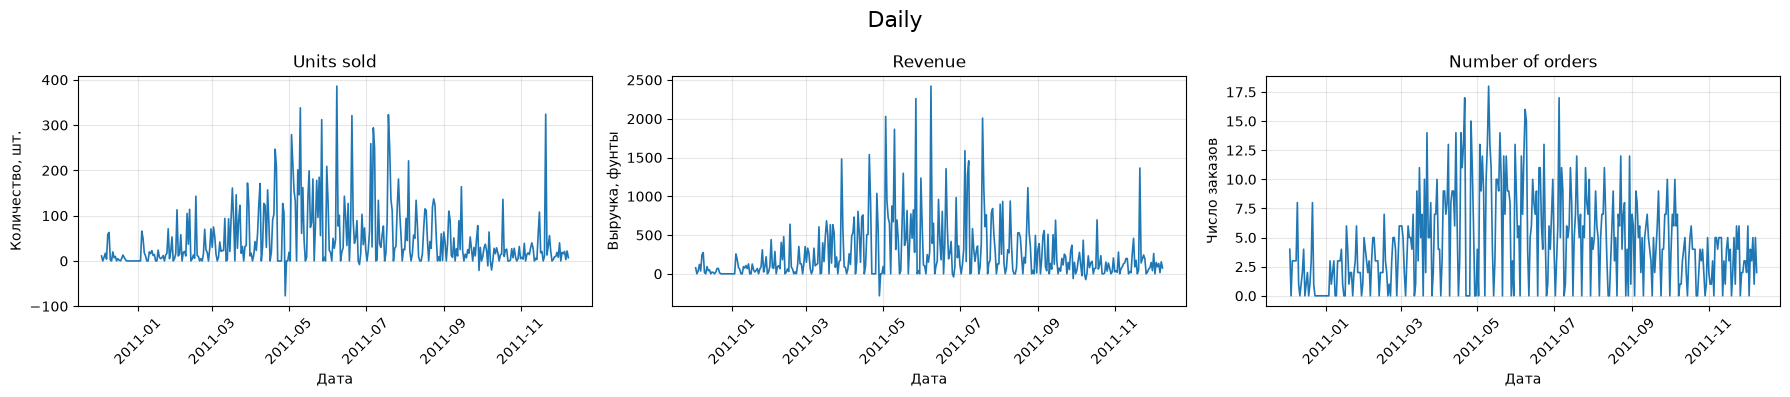

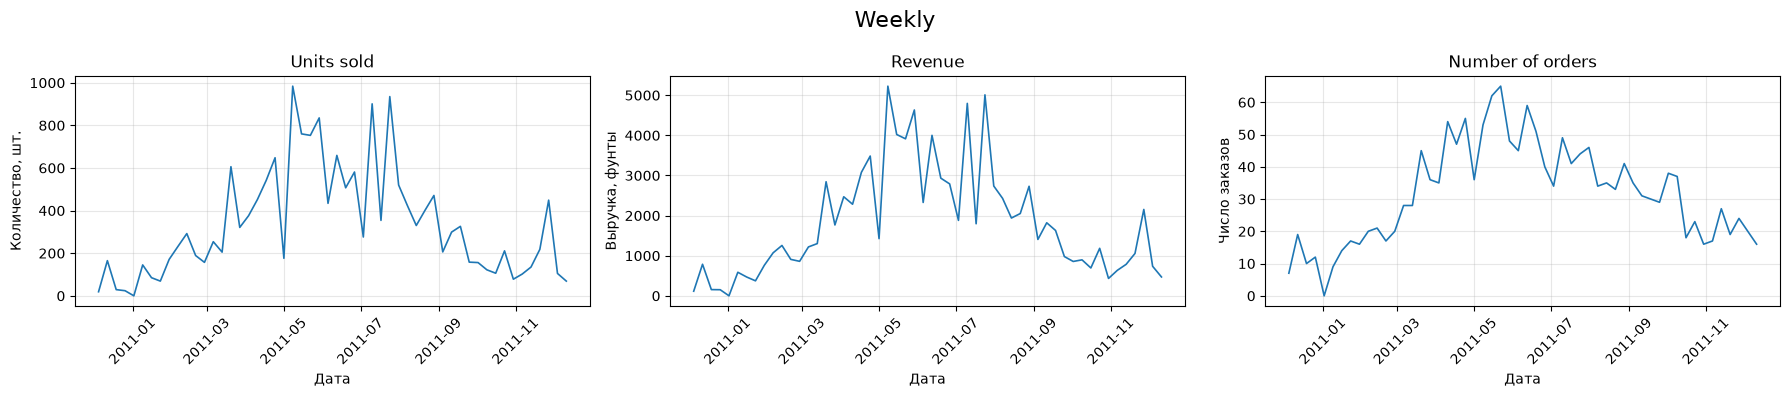

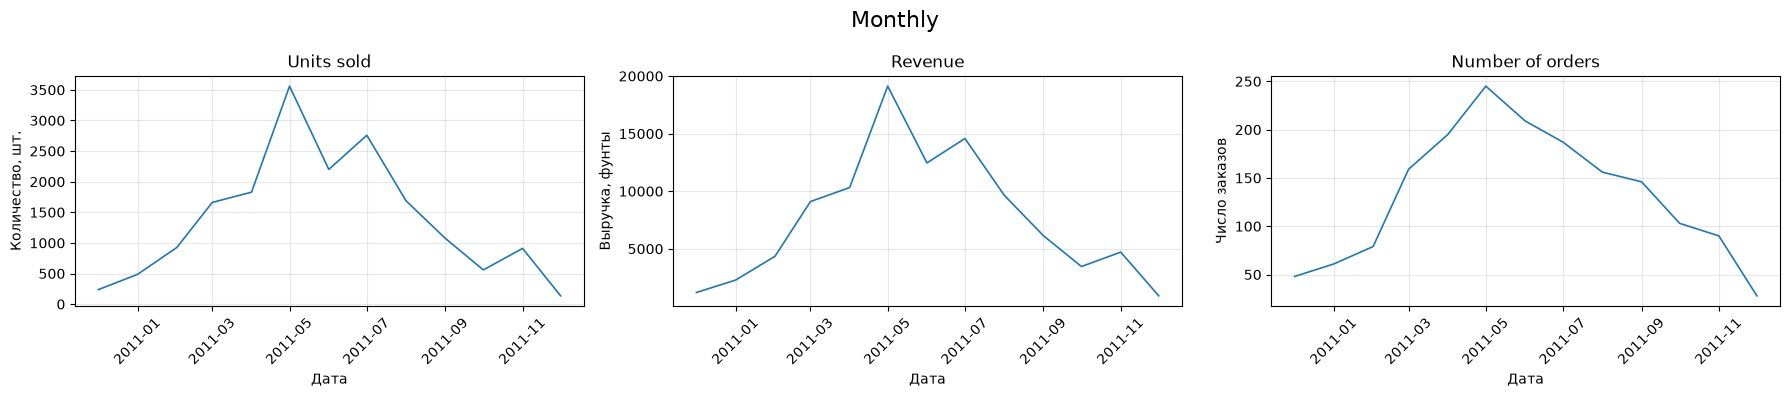

In [1088]:
def plot_aggregation(agg_df, name: str | None = None):
    columns = {
        "Quantity":  "Units sold",
        "Revenue":   "Revenue",
        "InvoiceNo": "Number of orders",
    }

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    units = {
        "Quantity":  "Количество, шт.",
        "Revenue":   "Выручка, фунты",
        "InvoiceNo": "Число заказов",
    }

    for ax, (column, label) in zip(axes, columns.items()):
        ax.plot(agg_df.index, agg_df[column], linewidth=1.2)
        
        ax.set_title(label)
        ax.set_xlabel("Дата")
        ax.set_ylabel(units[column])

        ax.grid(alpha=0.3)
        ax.tick_params(axis="x", rotation=45)

    if name:
        fig.suptitle(name, fontsize=16)
    fig.tight_layout()
    plt.show()

plot_aggregation(d, name='Daily')
plot_aggregation(w, name='Weekly')
plot_aggregation(m, name='Monthly')

Признак выручки имеет смысл поскольку `UnitPrice` для нашего товара не фиксированна, хотя графики продаж и выручки конечно очень похожи  

In [1089]:
df.loc[df["StockCode"] == P_STOCKCODE, "UnitPrice"].value_counts().sort_index()

UnitPrice
0.00        1
3.74        1
3.75       13
4.15      107
4.30        2
4.65       71
4.95     1239
4.96        8
5.79        8
8.29        7
8.47       12
9.13        2
9.32       15
10.79     239
12.95       1
15.79       1
Name: count, dtype: int64

Посмотрим на наложенные нормализованные графики двух признаков

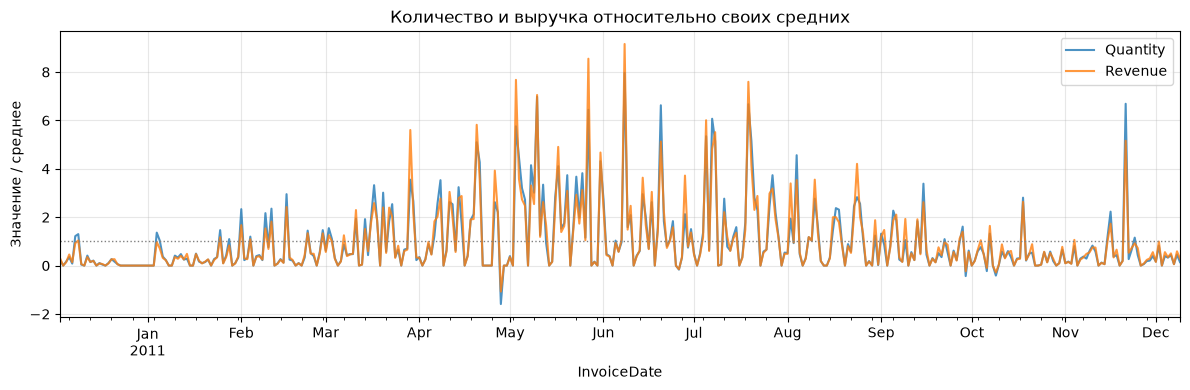

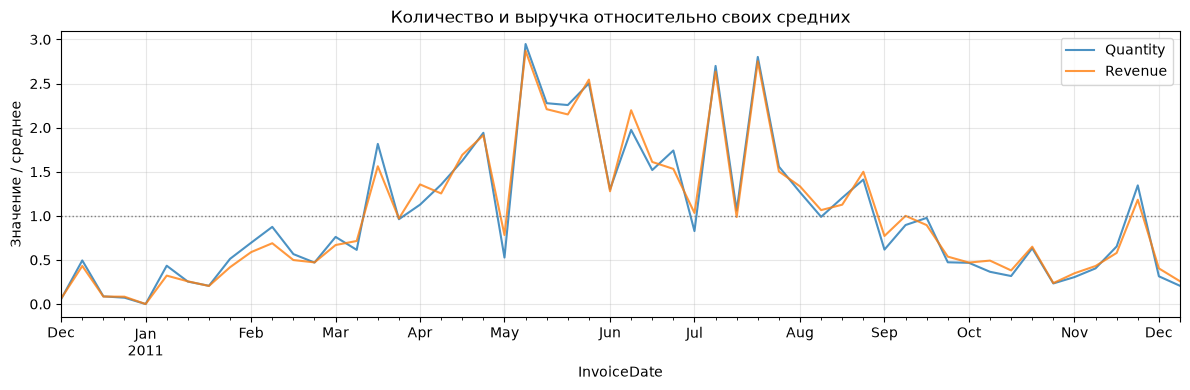

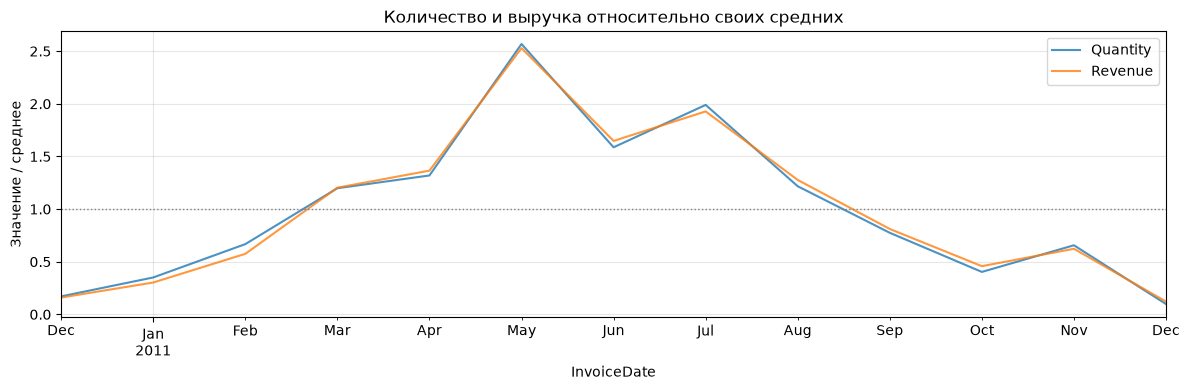

In [1090]:
def compare_quantity_revenue(agg_df):
    cols = ["Quantity", "Revenue"]
    normalized = agg_df[cols] / agg_df[cols].mean()

    ax = normalized.plot(figsize=(12, 4), alpha=0.8)
    ax.set_title("Количество и выручка относительно своих средних")
    ax.set_ylabel("Значение / среднее")
    ax.axhline(1, color="gray", linestyle=":", linewidth=1)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

compare_quantity_revenue(d)
compare_quantity_revenue(w)
compare_quantity_revenue(m)

## Шаг 2. Оценка качества данных
---

### 2.1. Пропуски
#### 2.1.1. Пропуски в исходной таблице

In [1091]:
# столбцы с пропусками
missing = df.isna().sum()
missing[missing > 0]

Description      1454
CustomerID     135080
dtype: int64

Пропуски у нас есть только в столбцах `Description` и `CustomerID`. Посмотрим на несколько строк у которых эти столбцы с пропусками

In [1092]:
df.loc[df["Description"].isna()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0,False
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0,False
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,False
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,False
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,False
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,False
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,False
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0,False


In [1093]:
df.loc[df["CustomerID"].isna()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom,0.00,False
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom,2.51,False
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02,False
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom,3.40,False
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom,3.32,False
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom,14.94,False
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom,5.02,False
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom,4.30,False
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom,3.87,False
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom,4.73,False


Соберем статистику по строкам с пропущенными `Description` и `CustomerID`

In [1094]:
for col in ['Description', 'CustomerID']:
    print(f'Столбец: {col}')

    # Строки с пропуском в выбранном столбце, без самого столбца
    subset = df.loc[df[col].isna()].drop(columns=col)

    # Статистика по всем остальным столбцам
    display(subset.describe(include="all").T)

# Пересечения пропусков
display(subset.isna().sum())

Столбец: Description


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,1454.0,1454.0,536414.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1454.0,960.0,35965.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1454.0,NaN,NaN,NaN,-9.359697,-3667.0,-24.0,-3.0,4.0,5568.0,243.238758
InvoiceDate,1454,NaN,NaN,NaN,2011-05-22 18:40:24.883081,2010-12-01 11:52:00,2011-03-22 17:04:15,2011-05-03 13:35:30,2011-08-04 15:42:45,2011-12-08 14:06:00,NaN
UnitPrice,1454.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CustomerID,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,1454,1,United Kingdom,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,1454.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
IsCancelled,1454,1,False,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Столбец: CustomerID


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,135080.0,3710.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,135080,3810,DOT,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,133626,3554,DOTCOM POSTAGE,693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,135080.0,NaN,NaN,NaN,1.995573,-9600.0,1.0,1.0,3.0,5568.0,66.696153
InvoiceDate,135080,NaN,NaN,NaN,2011-06-16 03:03:12.611637,2010-12-01 11:52:00,2011-02-21 18:10:00,2011-06-27 15:27:00,2011-10-11 16:37:00,2011-12-09 10:26:00,NaN
UnitPrice,135080.0,NaN,NaN,NaN,8.076577,-11062.06,1.63,3.29,5.45,17836.46,151.900816
Country,135080,9,United Kingdom,133600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,135080.0,NaN,NaN,NaN,10.71722,-17836.46,2.46,4.96,10.79,13541.33,157.967893
IsCancelled,135080,2,False,134697,NaN,NaN,NaN,NaN,NaN,NaN,NaN


InvoiceNo         0
StockCode         0
Description    1454
Quantity          0
InvoiceDate       0
UnitPrice         0
Country           0
Revenue           0
IsCancelled       0
dtype: int64

Из интересного, видно что `UnitPrice` для всех строк с пропуском по `Description` нулевая. Также `Quantity` в среднем отрицательное. В 1454 строках пропуски есть по обоим столбцам. Для строк с пропусками по `CustomerID` ничего примечательного не обнаружено

Посмотрим на уникальные коды товаров `StockCode` для товаров с пропусками по `Description` и проверим, что для нашего выбранного товара нет пропусков

In [1095]:
display(
    df.loc[df["Description"].isna(), "StockCode"].value_counts(dropna=False)
)
assert not df.loc[df["Description"].isna(), "StockCode"].eq(P_STOCKCODE).any(), f'{P_STOCKCODE} has missing Description'

StockCode
35965    10
23084    10
22084     9
22451     6
21784     5
         ..
22689     1
84581     1
23406     1
21620     1
85175     1
Name: count, Length: 960, dtype: int64

#### 2.1.2. Пропуски во времени для выбранного товара

Проверим также пропуски в дневной агрегации выручки выбранного товара. Рассмотрим период от первой до последней зарегистрированной операции с этим товаром. Отдельно проверим отсутствующие календарные даты, пропущенные значения и дни с нулевой выручкой.

In [1096]:
def missing_analysis(d, w, m):
    rows = []
    for name, frame, freq in [
        ("Дневная",   d, "D"),
        ("Недельная", w, "W-SUN"),
        ("Месячная",  m, "MS")]:

        revenue = frame["Revenue"]

        calendar = pd.date_range(revenue.index.min(), revenue.index.max(), freq=freq)
        missing_dates = calendar.difference(revenue.index)

        rows.append({
            'Агрегация':                    name,
            'Период':                       f'{revenue.index.min():%d.%m.%Y} - {revenue.index.max():%d.%m.%Y}',
            'Отсутствующих дат':            len(missing_dates),
            'Пропусков Revenue':            revenue.isna().sum(),
            'Дней с нулевой выручкой':      revenue.eq(0).sum(),
            'Доля дней с нулевой выручкой': revenue.eq(0).sum() / len(revenue)
        })

        if missing_dates.tolist():
            print(f"{name}:")
            print("Отсутствующие периоды:", missing_dates.tolist())

    display(pd.DataFrame(rows).set_index("Агрегация").round(2))

missing_analysis(d, w, m)

,Период,Отсутствующих дат,Пропусков Revenue,Дней с нулевой выручкой,Доля дней с нулевой выручкой
Агрегация,,,,,
Дневная,03.12.2010 - 09.12.2011,0,0,76,0.20
Недельная,05.12.2010 - 11.12.2011,0,0,1,0.02
Месячная,01.12.2010 - 01.12.2011,0,0,0,0.00


При агрегации через `resample` сумма за пустой интервал равна нулю. Поэтому календарь без разрывов и отсутствие `NaN` ещё не означают, что данные полные. После очистки проверим, откуда взялись нулевые дни: по товару не было записей, операции удалили фильтры или за этот день нет записей по всему магазину.

### 2.2. Выбросы

#### 2.2.1. Выбросы по всем товарам

Поищем выбросы среди `Quantity` и `UnitPrice` по всем товарам. Остальные признаки либо не численные, либо порожденны этими двумя. С нечисленными будем разбираться дальше

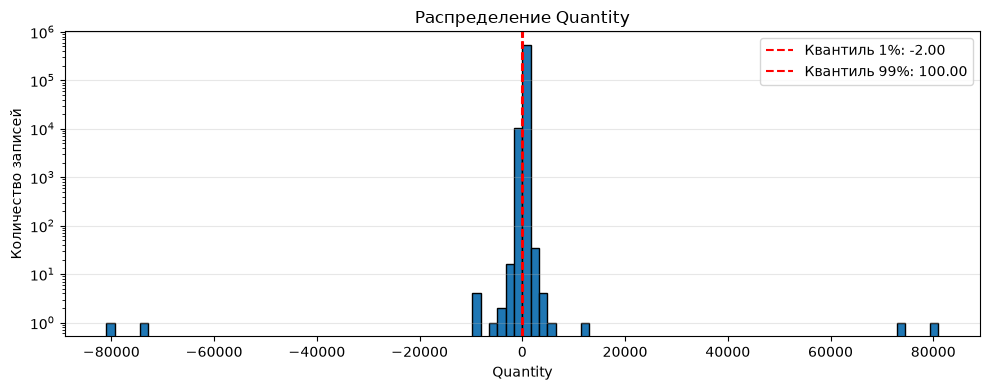

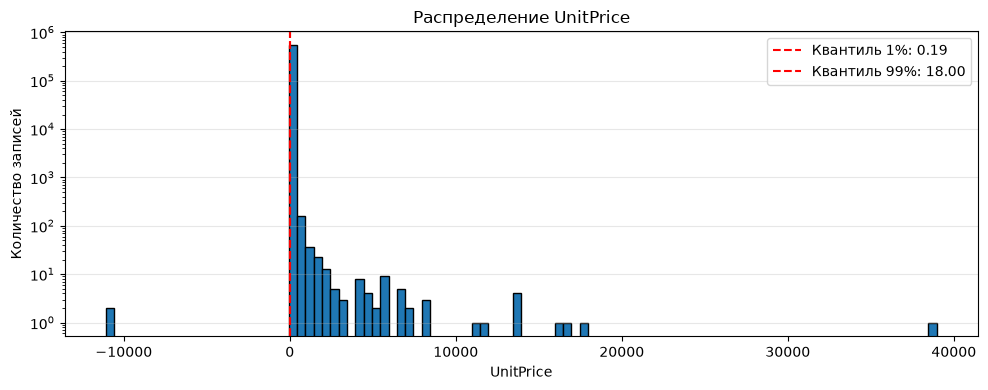

In [1097]:
def plot_histogram(df, column, 
                       bins: int | str | None = 100, 
                       log=False, 
                       lower_q=0.01, 
                       upper_q=0.99,
                       magnify: bool = False):
    values = df[column].dropna()
    lower, upper = values.quantile([lower_q, upper_q])

    fig, ax = plt.subplots(figsize=(10, 4))

    if magnify:
        padding = (upper - lower) * 0.1
        left, right = lower - padding, upper + padding

        ax.hist(
            values, 
            bins='auto' if bins is None else bins, 
            range=(left, right),
            edgecolor='black'
        )
    else:
        ax.hist(
            values, 
            bins='auto' if bins is None else bins, 
            edgecolor='black'
        )

    ax.axvline(lower, color="red", linestyle="--",
               label=f"Квантиль {lower_q:.0%}: {lower:.2f}")
    ax.axvline(upper, color="red", linestyle="--",
               label=f"Квантиль {upper_q:.0%}: {upper:.2f}")

    ax.set_title(f"Распределение {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Количество записей")

    if log:
        ax.set_yscale("log")

    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

plot_histogram(df, "Quantity",  bins=100, log=True, lower_q=0.01, upper_q=0.99, magnify=False)
plot_histogram(df, "UnitPrice", bins=100, log=True, lower_q=0.01, upper_q=0.99, magnify=False)

Посмотрим на строки у которых `UnitPrice` $\in [10000, 20000]$ 

In [1098]:
mask = df["UnitPrice"].between(10000, 20000)

print(f'Кол-во строк: {mask.sum()}')
display(df.loc[mask])

Кол-во строк: 9


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,-13541.33,True
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33,False
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom,-13474.79,True
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,-13541.33,True
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom,-16888.02,True
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom,-16453.71,True
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06,False
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,11586.50,NaN,United Kingdom,-11586.50,True
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom,-17836.46,True


Увеличим масштаб графиков (посмотрим на основную массу данных)

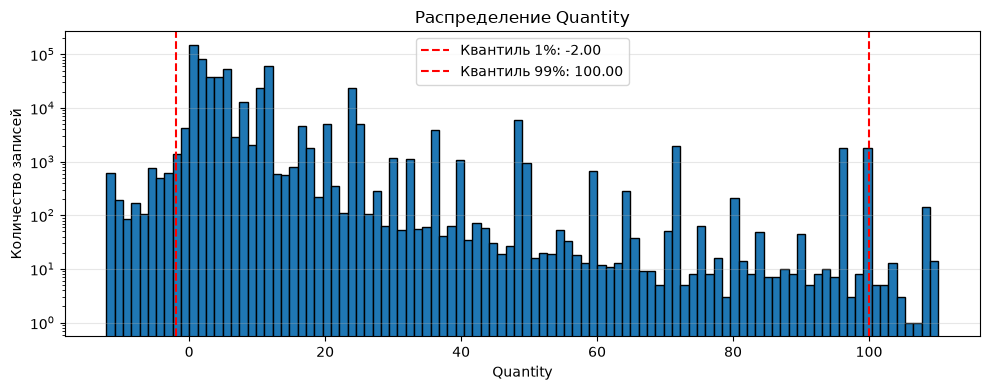

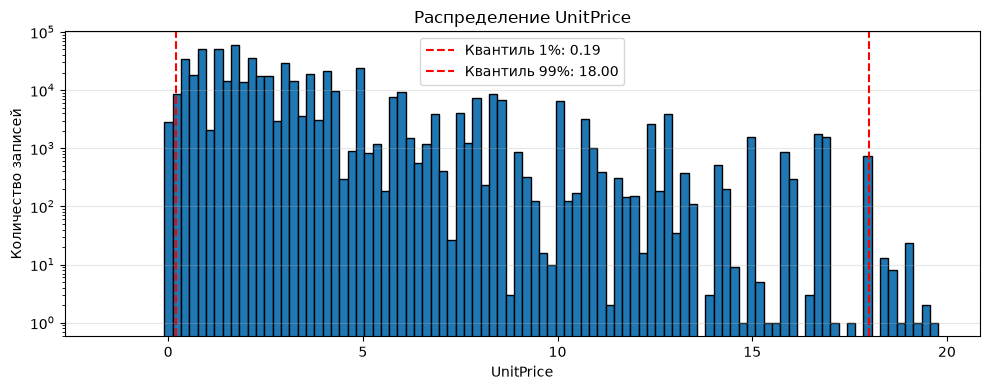

In [1099]:
plot_histogram(df, "Quantity",  bins=100, log=True, lower_q=0.01, upper_q=0.99, magnify=True)
plot_histogram(df, "UnitPrice", bins=100, log=True, lower_q=0.01, upper_q=0.99, magnify=True)

Гистограммы и квантили показали, что крайние значения `Quantity` и `UnitPrice` сильно отличаются от основной массы наблюдений. Описание датасета не объясняет смысл отрицательных значений, поэтому однозначно считать их ошибками или возвратами нельзя. Большие положительные значения также могут соответствовать реальным операциям, например оптовым заказам. Даже редкость высоких цен (всего 9 строк с `UnitPrice` от 10 000 до 20 000) сама по себе не доказывает ошибку. Поэтому рассматриваем эти записи как потенциальные выбросы, а пороги их исключения принимаем как допущение для дальнейшего анализа.

#### 2.2.2. Выбросы дневной выручки нашего товара

Теперь выделим потенциальные выбросы дневной выручки по правилу 1,5 IQR.

Границы IQR: [-492.71, 875.77]
Потенциальных выбросов: 24


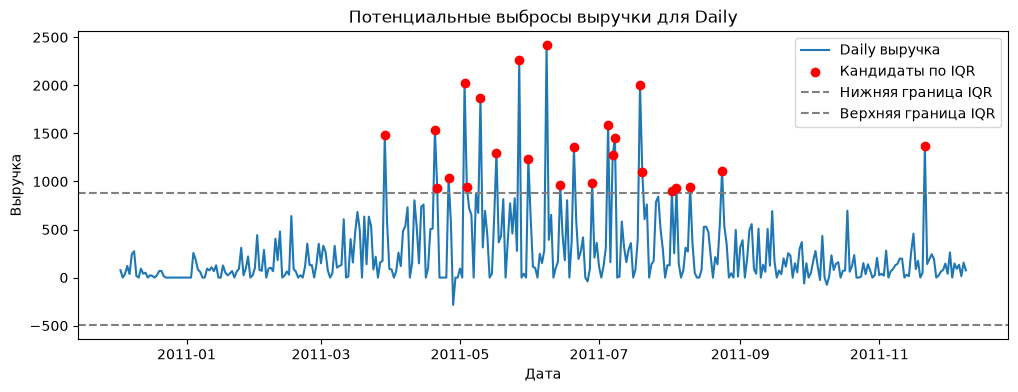

Границы IQR: [-2034.20, 5484.66]
Потенциальных выбросов: 0


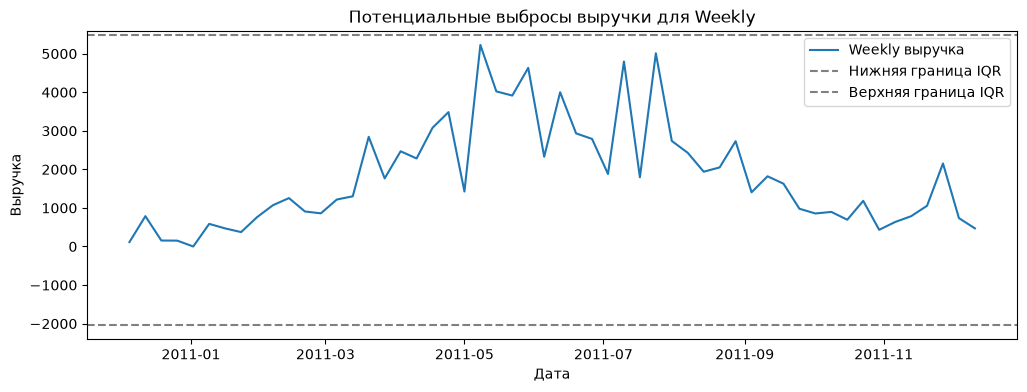

Границы IQR: [-6830.98, 20616.78]
Потенциальных выбросов: 0


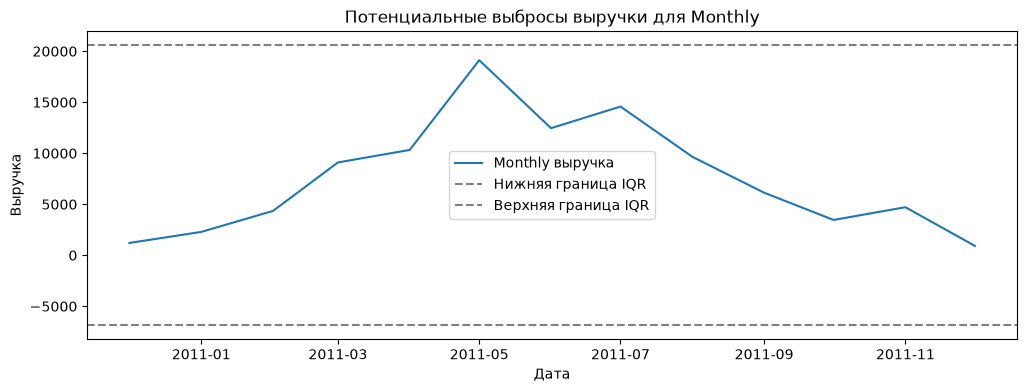

In [1100]:
def plot_iqr_outliers(agg_df, name: str):
    revenue = agg_df["Revenue"]

    q1, q3 = revenue.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    outliers = revenue.loc[(revenue < lower) | (revenue > upper)]

    print(f"Границы IQR: [{lower:.2f}, {upper:.2f}]")
    print(f"Потенциальных выбросов: {len(outliers)}")

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(revenue.index, revenue.to_numpy(), label=f"{name} выручка")

    if not outliers.empty:
        ax.scatter(
            outliers.index,
            outliers.to_numpy(),
            color="red",
            label="Кандидаты по IQR",
            zorder=3,
        )

    ax.axhline(lower, color="gray", linestyle="--", label="Нижняя граница IQR")
    ax.axhline(upper, color="gray", linestyle="--", label="Верхняя граница IQR")

    ax.set(title=f"Потенциальные выбросы выручки для {name}",
           xlabel="Дата", 
           ylabel="Выручка")
    ax.legend()

    plt.show()

plot_iqr_outliers(d, name='Daily')
plot_iqr_outliers(w, name='Weekly')
plot_iqr_outliers(m, name='Monthly')

Выделенные значения сохраняем: глобальное правило IQR не учитывает изменение уровня и сезонность ряда, поэтому может отмечать дни повышенного спроса. Без дополнительных свидетельств ошибки оснований удалять такие наблюдения недостаточно.

### 2.3. Визуализация до обработки

см. конец раздела 1.4. 

### 2.4. Обработка и обоснование

В работе рассматриваем платные продажи выбранного товара: операции с положительными количеством и ценой, без отмен.

В описании используемого датасета не раскрывается смысл отрицательных значений и причины экстремальных количеств и цен, а уточнить обстоятельства отдельных операций мы не можем. Поэтому обработка данных опирается на указанные допущения и наблюдаемые свойства записей. Исключение записи из анализа само по себе не означает, что она ошибочна.

#### 2.4.1. Пропуски

Удаляем строки с пропуском `Description`: у всех них нулевая цена, поэтому исключаем их из анализа платных продаж. Для выбранного товара таких строк нет, значит, его ряд не изменится.

Пропуски `CustomerID` оставляем: идентификатор покупателя не нужен для агрегации продаж товара по времени. Его отсутствие не мешает использовать количество, цену и дату операции. А дефекта строк с пропусками `CustomerID` анализ не выявил.

In [1101]:
before = df[["Description", "CustomerID"]].isna().sum()
n_before = len(df)

df = df.dropna(subset=["Description"]).copy()

print(f"Удалено строк: {n_before - len(df)}")
print(f"Осталось строк: {len(df)}")

display(pd.DataFrame({
    "Пропусков до": before,
    "Пропусков после": df[["Description", "CustomerID"]].isna().sum(),
}))

Удалено строк: 1454
Осталось строк: 540455


,Пропусков до,Пропусков после
Description,1454,0
CustomerID,135080,133626


#### 2.4.1. Выбросы

Согласно принятым допущениям, рассматриваем платные продажи с положительными количеством и ценой, поэтому исключаем строки с `Quantity <= 0` или `UnitPrice <= 0`. Дополнительно исключаем операции с `Quantity > 20 000` или `UnitPrice > 10 000`, чтобы ограничить влияние экстремальных значений. Эти верхние пороги принимаем как рабочее допущение, поскольку подтвердить ошибочность таких записей по доступным данным нельзя.

In [1102]:
n_before = len(df)

df = df.loc[
    df["Quantity"].between(0, 20_000, inclusive="right")
    & df["UnitPrice"].between(0, 10_000, inclusive="right")
].copy()

print(f"Удалено строк: {n_before - len(df)}")
print(f"Осталось строк: {len(df)}")

display(df[["Quantity", "UnitPrice"]].describe())

Удалено строк: 10355
Осталось строк: 530100


,Quantity,UnitPrice
count,530100.000000,530100.000000
mean,10.249319,3.861236
std,37.793615,26.712399
min,1.000000,0.001000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,4800.000000,8142.750000


#### 2.4.1. Прочее

##### Дупликаты

In [1103]:
print(f'duplicates: {df.duplicated().sum()}')
df[df.duplicated(keep=False)].sort_values("Description", ascending=False)

duplicates: 5226


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
104362,545166,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2011-02-28 14:03:00,0.85,17027.0,United Kingdom,0.85,False
104355,545166,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2011-02-28 14:03:00,0.85,17027.0,United Kingdom,0.85,False
468850,576559,23151,ZINC SWEETHEART SOAP DISH,1,2011-11-15 13:19:00,2.49,14711.0,United Kingdom,2.49,False
468873,576559,23151,ZINC SWEETHEART SOAP DISH,1,2011-11-15 13:19:00,2.49,14711.0,United Kingdom,2.49,False
499582,578678,84836,ZINC METAL HEART DECORATION,1,2011-11-24 19:59:00,1.25,17841.0,United Kingdom,1.25,False
...,...,...,...,...,...,...,...,...,...,...
460098,575895,23345,DOLLY GIRL BEAKER,1,2011-11-11 14:50:00,1.25,17052.0,United Kingdom,1.25,False
160509,550459,72800B,4 PURPLE FLOCK DINNER CANDLES,1,2011-04-18 13:17:00,2.55,18116.0,United Kingdom,2.55,False
483390,577503,72800B,4 PURPLE FLOCK DINNER CANDLES,1,2011-11-20 12:34:00,2.55,18110.0,United Kingdom,2.55,False
483414,577503,72800B,4 PURPLE FLOCK DINNER CANDLES,1,2011-11-20 12:34:00,2.55,18110.0,United Kingdom,2.55,False


In [1104]:
# drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(f'duplicates: {df.duplicated().sum()}')

duplicates: 0


##### Унификация типов

In [1105]:
obj_cols = df.select_dtypes(include=['object'], exclude=['string']).columns
for obj_col in obj_cols:
    display(df[obj_col].map(type).value_counts())

InvoiceNo
<class 'int'>    524874
Name: count, dtype: int64

StockCode
<class 'int'>    472251
<class 'str'>     52623
Name: count, dtype: int64

Description
<class 'str'>    524874
Name: count, dtype: int64

In [1106]:
for col in obj_cols:
    print(f"\n{col}")
    types = df[col].map(type)

    for dtype in types.unique():
        examples = df.loc[types == dtype, col].head(5).tolist()
        print(f"  {dtype.__name__}: {examples}")


InvoiceNo
  int: [536365, 536365, 536365, 536365, 536365]

StockCode
  str: ['85123A', '84406B', '84029G', '84029E', 'POST']
  int: [71053, 22752, 21730, 22633, 22632]

Description
  str: ['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN', 'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.']


Приведем их к одному типу

In [1107]:
df["InvoiceNo"]   = df["InvoiceNo"].astype("int64")
df["StockCode"]   = df["StockCode"].astype("string")
df["Description"] = df["Description"].astype("string")

P_STOCKCODE = str(P_STOCKCODE)

In [1108]:
summary = pd.DataFrame({
    "dtype":    df.dtypes,
    "non_null": df.notna().sum(),
    "missing":  df.isna().sum(),
    "unique":   df.nunique(),
})
display(summary)

,dtype,non_null,missing,unique
InvoiceNo,int64,524874,0,19956
StockCode,string,524874,0,3920
Description,string,524874,0,4024
Quantity,int64,524874,0,373
InvoiceDate,datetime64[us],524874,0,18496
UnitPrice,float64,524874,0,1289
CustomerID,float64,392690,132184,4337
Country,str,524874,0,38
Revenue,float64,524874,0,4902
IsCancelled,boolean,524874,0,1


## Шаг 3. Визуальный и описательный анализ
---

### 3.1. График временного ряда

Отфильтруем только наш товар и посмотрим на данные после обработки.

Также исключим первую и последнюю неполные недели и неполный декабрь 2011 года. Их суммарная выручка охватывает меньше дней, поэтому напрямую сравнивать её с полными периодами некорректно. Дневной ряд оставляем без изменений.

In [1109]:
df = df.loc[df["StockCode"] == P_STOCKCODE]

,dtype,non_null,missing,unique
InvoiceNo,int64,1699,0,1685
StockCode,string,1699,0,1
Description,string,1699,0,1
Quantity,int64,1699,0,58
InvoiceDate,datetime64[us],1699,0,1674
UnitPrice,float64,1699,0,14
CustomerID,float64,1389,310,708
Country,str,1699,0,20
Revenue,float64,1699,0,117
IsCancelled,boolean,1699,0,1


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,1699.0,NaN,NaN,NaN,557047.287228,536864.0,549840.5,556049.0,563750.5,581497.0,9972.286708
StockCode,1699,1,47566,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1699,1,PARTY BUNTING,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1699.0,NaN,NaN,NaN,10.761036,1.0,3.0,4.0,8.0,200.0,20.382257
InvoiceDate,1699,NaN,NaN,NaN,2011-06-14 06:05:30.582695,2010-12-03 11:27:00,2011-04-12 13:57:30,2011-06-08 13:00:00,2011-08-19 10:23:00,2011-12-09 10:23:00,NaN
UnitPrice,1699.0,NaN,NaN,NaN,5.797928,3.75,4.95,4.95,4.95,15.79,2.137334
CustomerID,1389.0,NaN,NaN,NaN,15379.615551,12359.0,13888.0,15410.0,16927.0,18265.0,1712.372516
Country,1699,20,United Kingdom,1607,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,1699.0,NaN,NaN,NaN,58.531624,4.65,14.85,19.8,39.6,1542.97,117.436632
IsCancelled,1699,1,False,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN


duplicates: 0


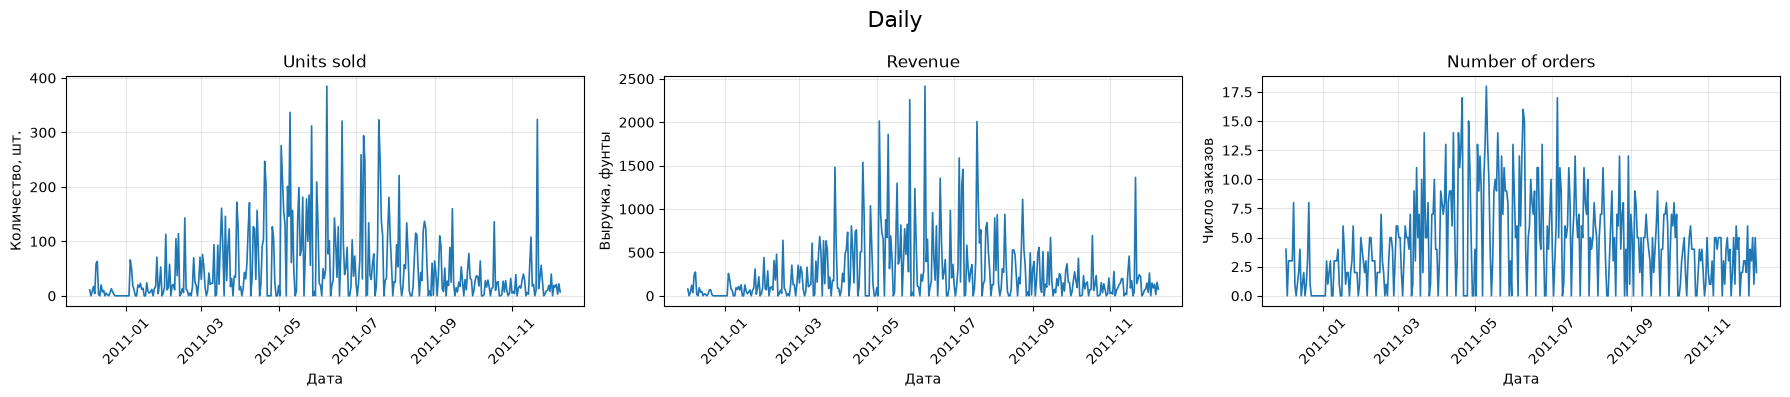

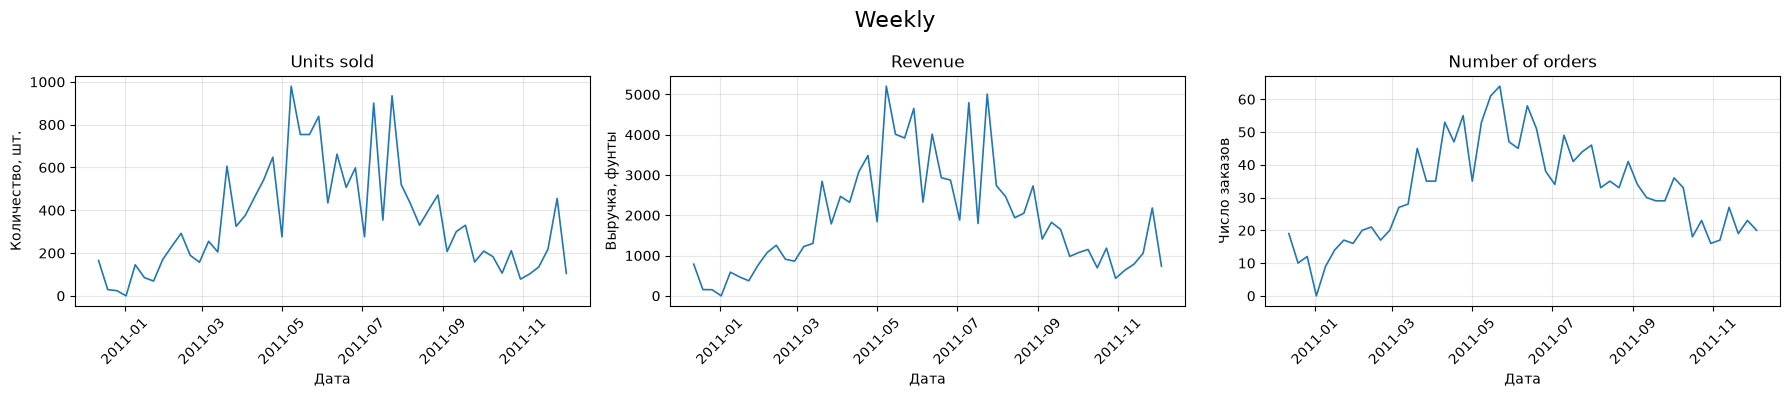

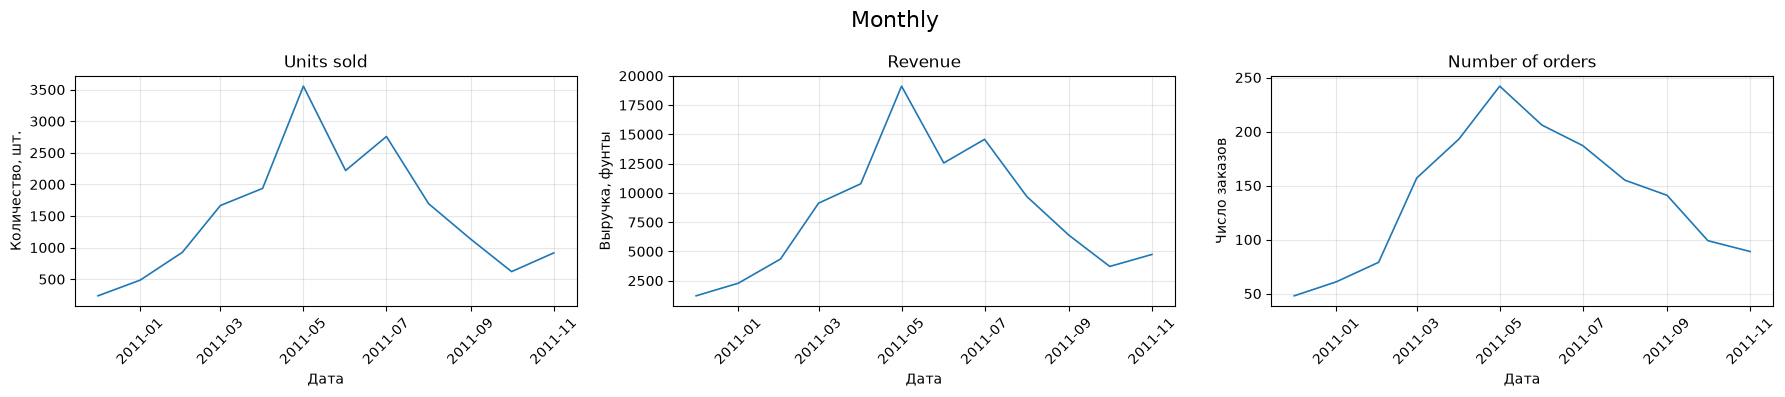

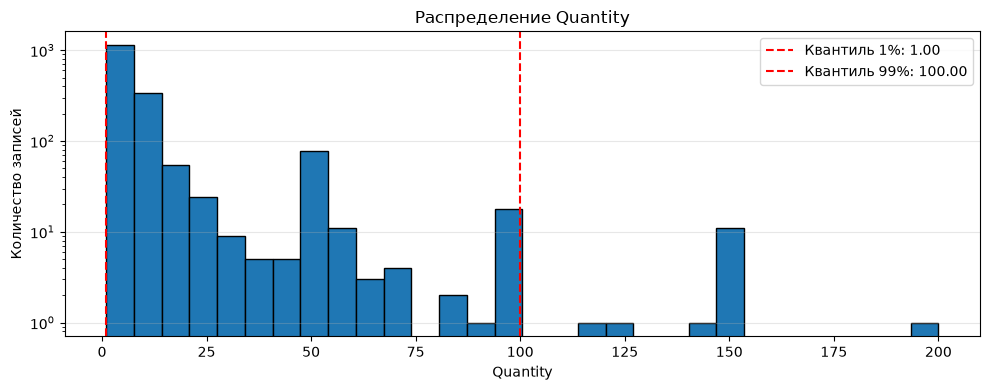

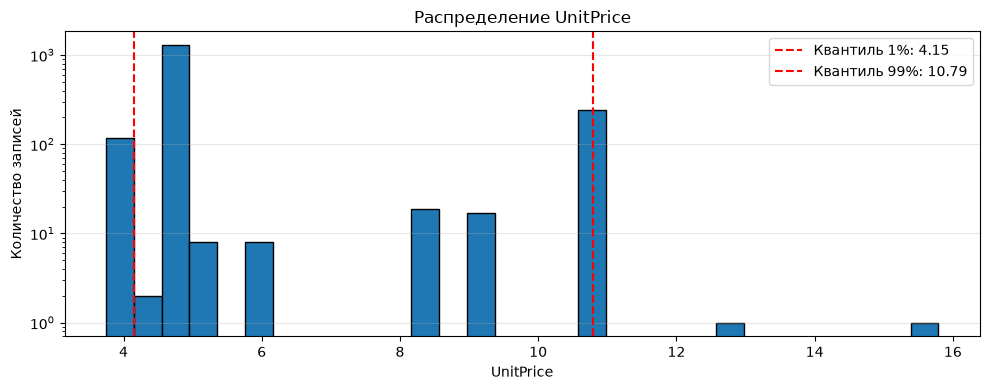

In [1110]:
# Описательный анализ
summary = pd.DataFrame({
    "dtype":    df.dtypes,
    "non_null": df.notna().sum(),
    "missing":  df.isna().sum(),
    "unique":   df.nunique(),
})
display(summary)

display(df.describe(include="all").T)

print(f'duplicates: {df.duplicated().sum()}')

# Визуальный анализ
aggregation_rule = {
    "Quantity":  "sum",
    "Revenue":   "sum",
    "InvoiceNo": "nunique",
}

d, w, m = aggregate(df, P_STOCKCODE, aggregation_rule).values()

# исключим неполные периоды на границах датасета
w = w.iloc[1:-1].copy()  # первая и последняя недельные суммы
m = m.iloc[:-1].copy()   # последняя месячная сумма

plot_aggregation(d, name='Daily')
plot_aggregation(w, name='Weekly')
plot_aggregation(m, name='Monthly')

plot_histogram(df, "Quantity",  bins=30, log=True, lower_q=0.01, upper_q=0.99, magnify=False)
plot_histogram(df, "UnitPrice", bins=30, log=True, lower_q=0.01, upper_q=0.99, magnify=False)

Дальше будем работать с `Revenue` как с целевым признаком

#### Проверка происхождения нулевых дней

Для дней с нулевой выручкой проверим наличие записей в исходной таблице:
по всему магазину и по выбранному товару.

In [1111]:
raw = df_raw.copy()
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])

raw_product = raw.loc[
    raw["StockCode"].astype(str) == str(P_STOCKCODE)
]

# посчитаем записи в журнале, включая впоследствии исключённые
def daily_records(frame):
    return (
        frame.resample("D", on="InvoiceDate")
        .size()
        .reindex(d.index, fill_value=0)
    )

check = pd.DataFrame({
    "Revenue":             d["Revenue"],
    "Записей по магазину": daily_records(raw),
    "Записей по товару":   daily_records(raw_product),
})

zero_days = check.loc[check["Revenue"].eq(0)].copy()
zero_days["День недели"] = zero_days.index.day_name()

zero_days["Причина"] = "Нет записей по товару, другие товары есть"
zero_days.loc[
    zero_days["Записей по товару"].gt(0), "Причина"
] = "Записи по товару были, но исключены при очистке"
zero_days.loc[
    zero_days["Записей по магазину"].eq(0), "Причина"
] = "Нет записей по всему магазину"

display(zero_days["Причина"].value_counts().rename("Количество дней"))
display(pd.crosstab(zero_days["День недели"], zero_days["Причина"]))

# даты, когда отсутствуют записи по всему магазину
no_store_records = zero_days.loc[
    zero_days["Записей по магазину"].eq(0)
]
print("Даты без записей по магазину:")
print(no_store_records.index.strftime("%Y-%m-%d").tolist())

Причина
Нет записей по всему магазину                      69
Нет записей по товару, другие товары есть           7
Записи по товару были, но исключены при очистке     2
Name: Количество дней, dtype: int64

Причина,"Записи по товару были, но исключены при очистке",Нет записей по всему магазину,"Нет записей по товару, другие товары есть"
День недели,,,
Friday,0,4,0
Monday,0,6,1
Saturday,0,53,0
Sunday,2,3,4
Thursday,0,1,1
Tuesday,0,1,0
Wednesday,0,1,1


Даты без записей по магазину:
['2010-12-04', '2010-12-11', '2010-12-18', '2010-12-24', '2010-12-25', '2010-12-26', '2010-12-27', '2010-12-28', '2010-12-29', '2010-12-30', '2010-12-31', '2011-01-01', '2011-01-02', '2011-01-03', '2011-01-08', '2011-01-15', '2011-01-22', '2011-01-29', '2011-02-05', '2011-02-12', '2011-02-19', '2011-02-26', '2011-03-05', '2011-03-12', '2011-03-19', '2011-03-26', '2011-04-02', '2011-04-09', '2011-04-16', '2011-04-22', '2011-04-23', '2011-04-24', '2011-04-25', '2011-04-29', '2011-04-30', '2011-05-02', '2011-05-07', '2011-05-14', '2011-05-21', '2011-05-28', '2011-05-30', '2011-06-04', '2011-06-11', '2011-06-18', '2011-06-25', '2011-07-02', '2011-07-09', '2011-07-16', '2011-07-23', '2011-07-30', '2011-08-06', '2011-08-13', '2011-08-20', '2011-08-27', '2011-08-29', '2011-09-03', '2011-09-10', '2011-09-17', '2011-09-24', '2011-10-01', '2011-10-08', '2011-10-15', '2011-10-22', '2011-10-29', '2011-11-05', '2011-11-12', '2011-11-19', '2011-11-26', '2011-12-03']


Из 78 дней с нулевой выручкой в 7 нет записей по выбранному товару, хотя другие товары продавались. Ещё в 2 днях все операции товара исключены при очистке.

В остальных 69 днях записи отсутствуют по всему магазину: это все 53 субботы и 16 других дней. Субботние перерывы согласуются с недельным режимом работы или регистрации заказов, причину остальных установить нельзя.

В дальнейшем сохраняем нули, предполагая, что журнал полон, а отсутствие записей означает отсутствие продаж. Регулярность субботних перерывов поддерживает такое решение, но не доказывает полноту данных. Если часть записей утрачена, нули занижают выручку и искажают результаты анализа.

### 3.2. Основные описательные статистики и дополнительные характеристики для анализа продаж

In [1112]:
def revenue_stats(agg_df):
    """
    Возвращает описательные статистики выручки за период агрегации.

    count         -- число периодов с известной выручкой;
    mean, std     -- среднее и стандартное отклонение;
    min, max      -- минимальная и максимальная выручка;
    25%, 50%, 75% -- квартили (50% -- медиана);
    variance      -- дисперсия;
    range         -- размах (max - min);
    IQR           -- межквартильный размах (75% - 25%);
    CV            -- коэффициент вариации (std / mean), в долях;
    zero_share    -- доля периодов с нулевой выручкой.
    """

    revenue = agg_df["Revenue"]
    stats = revenue.describe()

    stats["variance"]   = revenue.var()
    stats["range"]      = revenue.max() - revenue.min()
    stats["CV"]         = revenue.std() / revenue.mean() if revenue.mean() != 0 else float("nan")
    stats["IQR"]        = revenue.quantile(0.75) - revenue.quantile(0.25)
    stats["zero_share"] = revenue.eq(0).sum() / len(revenue)

    return stats

display(pd.DataFrame({
    "Daily":   revenue_stats(d),
    "Weekly":  revenue_stats(w),
    "Monthly": revenue_stats(m),
}).round(2))

,Daily,Weekly,Monthly
count,372.00,52.00,12.00
mean,267.33,1901.16,8210.56
std,375.78,1348.07,5416.10
min,0.00,0.00,1207.74
25%,23.25,841.43,4190.04
50%,128.33,1717.20,7753.09
75%,362.59,2731.98,11222.88
max,2415.19,5206.44,19118.05
variance,141208.90,1817286.07,29334105.39
range,2415.19,5206.44,17910.31


Средняя дневная выручка составляет 267,33, а медианная - 128,33. Такое различие согласуется с правой асимметрией распределения (см. пункт 3.4.2.): отдельные дни с высокой выручкой заметно повышают среднее. Коэффициент вариации дневной выручки равен 1,41, что указывает на большой разброс относительно среднего уровня. Около 21% дней имеют нулевую выручку.

При недельной и месячной агрегации относительный разброс ниже: коэффициент вариации составляет 0,71 и 0,66 соответственно. Укрупнение интервалов сглаживает дневные колебания.

### 3.3. Изменение уровня и разброса значений во времени

Построим графики скользящего среднего и скользяшего стандартного отклонения

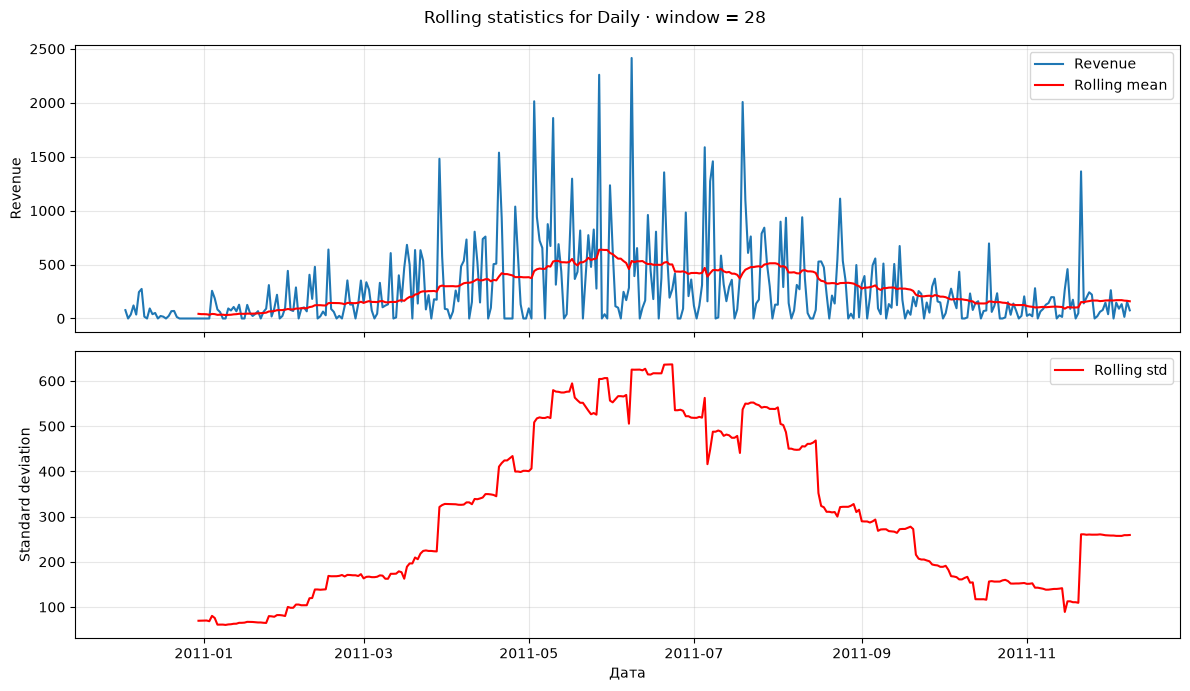

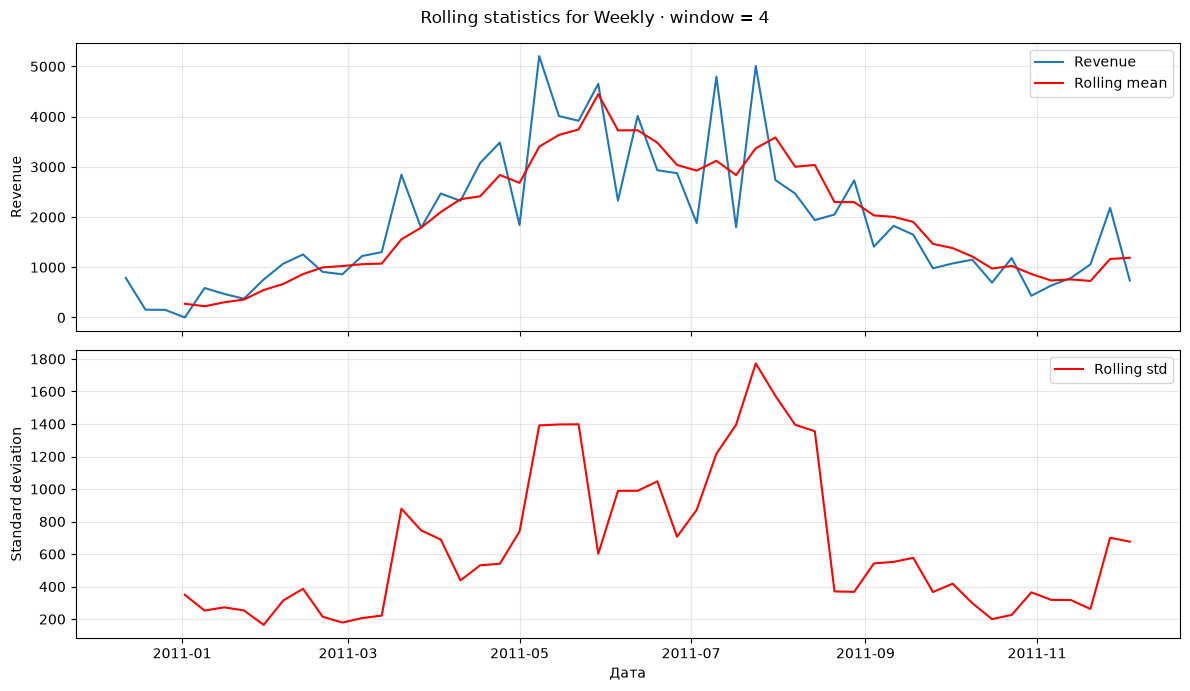

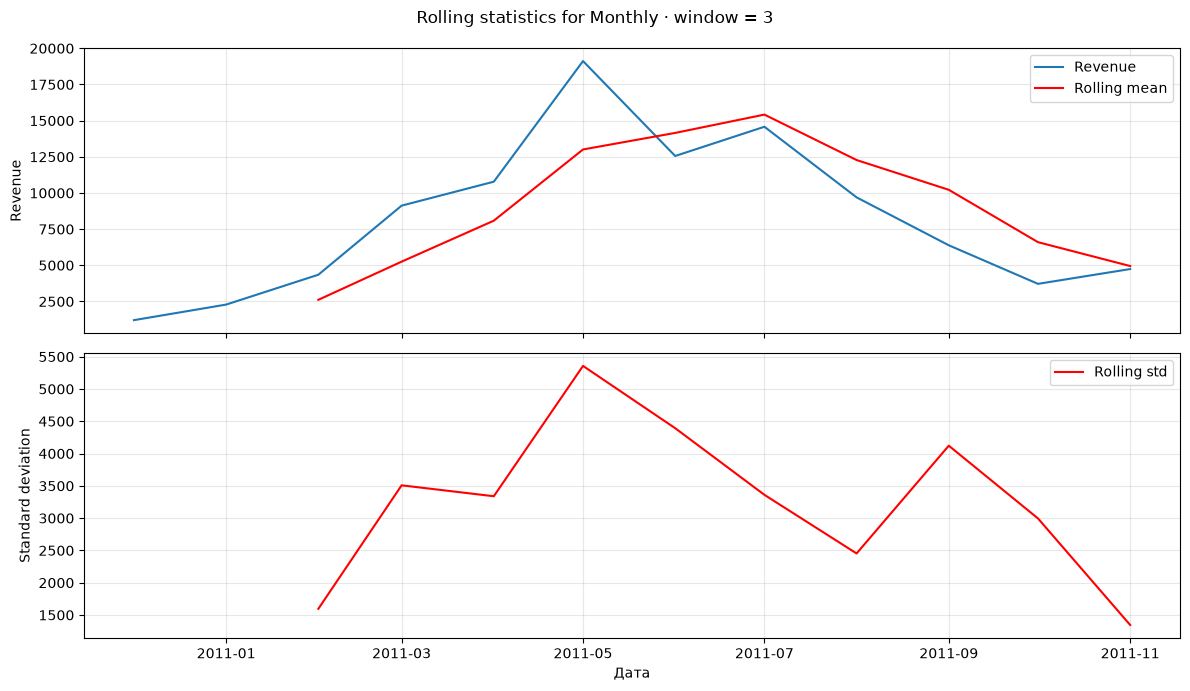

In [1113]:
def plot_rolling(agg_df, window, name: str | None = None, ylabel="Revenue"):
    revenue = agg_df["Revenue"]
    rolling = revenue.rolling(window)

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    axes[0].plot(revenue, label=ylabel)
    axes[0].plot(rolling.mean(), color='red', label="Rolling mean")
    axes[0].set_ylabel(ylabel)
    axes[1].set_xlabel("Дата")

    axes[1].plot(rolling.std(), color="red", label="Rolling std")
    axes[1].set_ylabel("Standard deviation")

    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)

    if name is not None:
        fig.suptitle(f"Rolling statistics for {name} · window = {window}")
    else:
        fig.suptitle(f"Rolling statistics · window = {window}")
    
    plt.tight_layout()
    plt.show()

plot_rolling(d, window=28, name='Daily')     # 28 дней
plot_rolling(w, window=4,  name='Weekly')    # 4 недели
plot_rolling(m, window=3,  name='Monthly')   # 3 месяца

### 3.4. Дополнительные графики для выявления закономерностей

#### 3.4.1. Boxplot дневной выручки по дням недели

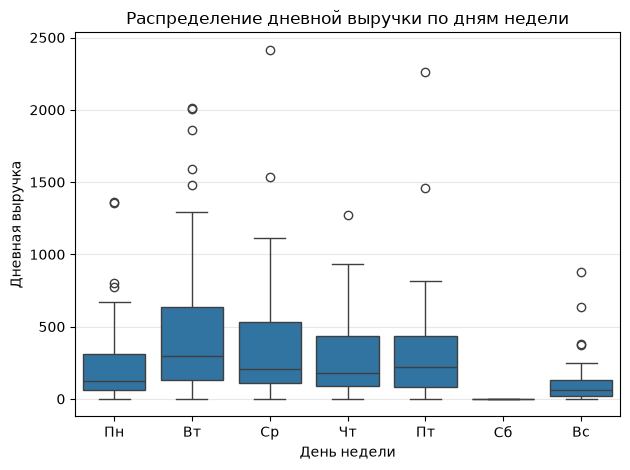

In [1114]:
def plot_weekday_boxplot(daily_df):
    sns.boxplot(
        x=daily_df.index.dayofweek,
        y=daily_df["Revenue"],
        order=range(7),
    )
    plt.xticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"])
    plt.xlabel("День недели")
    plt.ylabel("Дневная выручка")
    plt.title("Распределение дневной выручки по дням недели")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_weekday_boxplot(d)

Наибольшая медианная дневная выручка наблюдается во вторник. По выходным выручка ниже, причём субботние значения сосредоточены в нуле.

#### 3.4.2. Гистограмма выручки

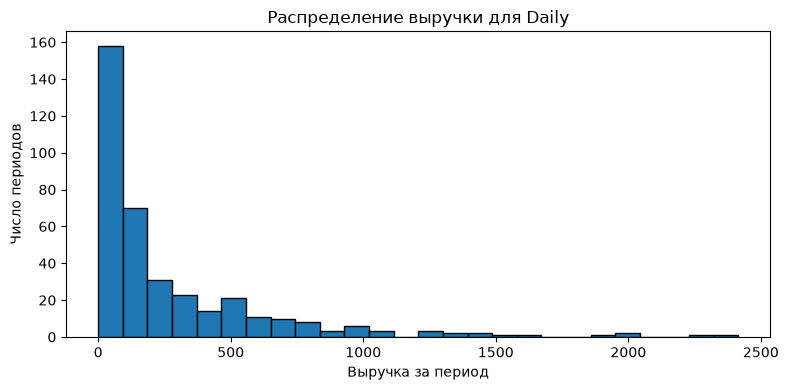

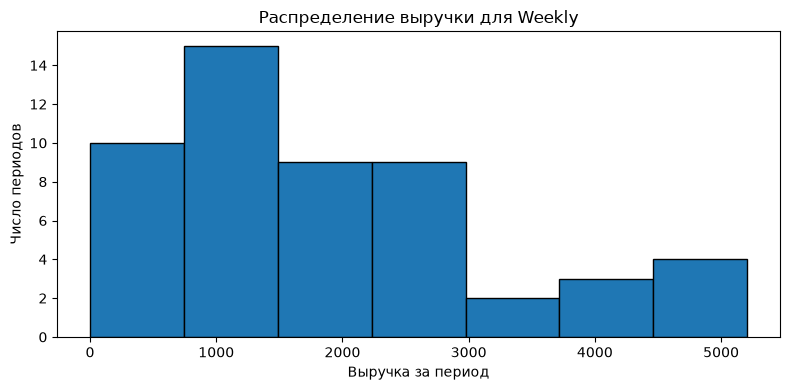

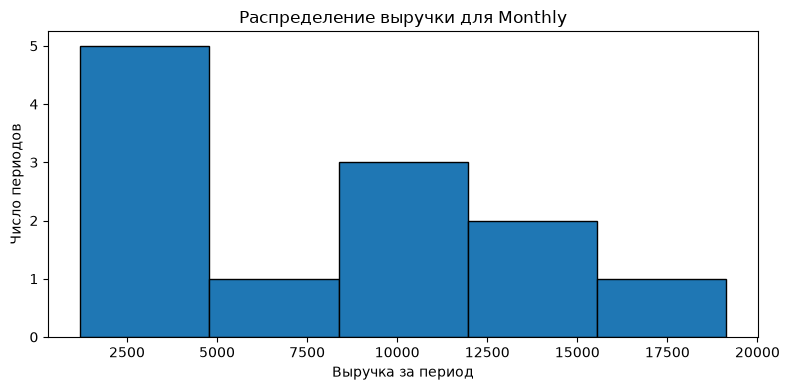

In [1115]:
def plot_revenue_hist(agg_df, bins: int | str | None = None, name: str | None = None):
    plt.figure(figsize=(8, 4))
    plt.hist(agg_df["Revenue"], bins="auto" if bins is None else bins, edgecolor="black")

    if name is not None:
        plt.title(f"Распределение выручки для {name}")
    else:
        plt.title("Распределение выручки")

    plt.xlabel("Выручка за период")
    plt.ylabel("Число периодов")
    plt.tight_layout()
    plt.show()

plot_revenue_hist(d, bins='auto', name='Daily')
plot_revenue_hist(w, bins='auto', name='Weekly')
plot_revenue_hist(m, bins='auto', name='Monthly')

Распределение дневной выручки имеет выраженную правую асимметрию: часто встречаются нулевые и небольшие значения, а высокие значения наблюдаются значительно реже.

#### 3.4.3. График автокорреляции (ACF)

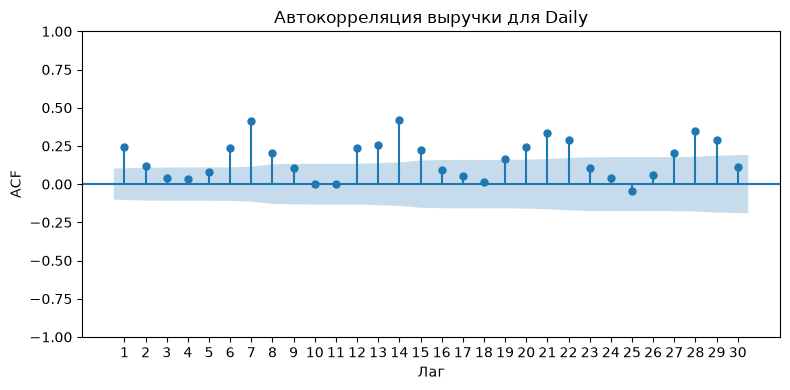

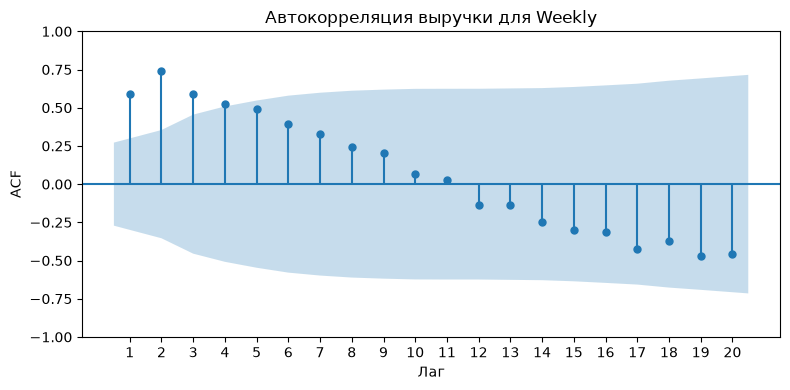

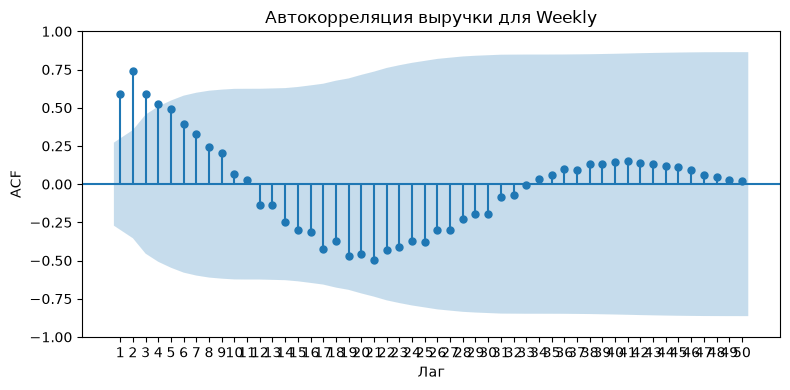

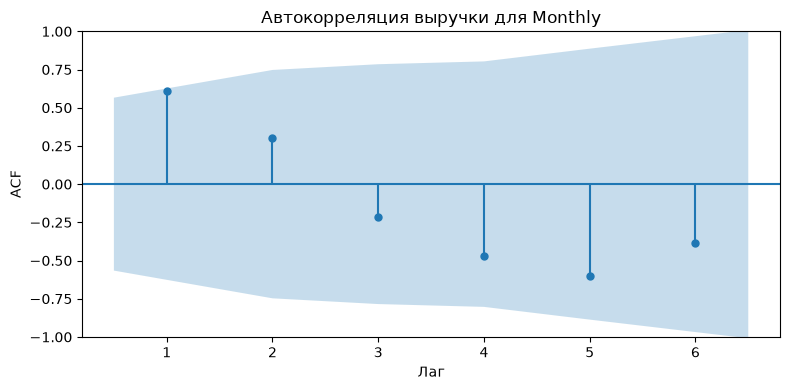

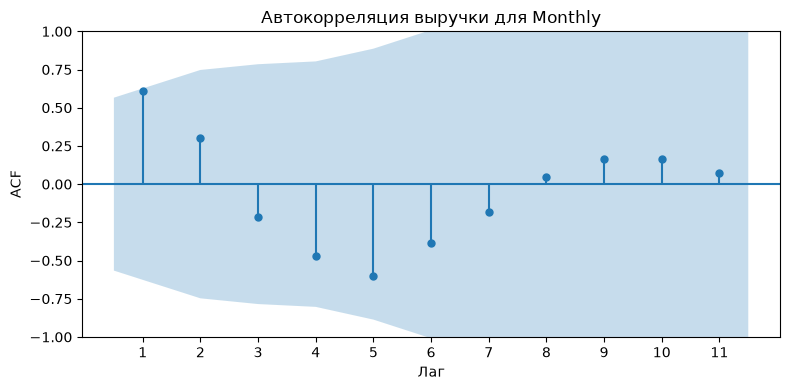

In [1116]:
def plot_revenue_acf(agg_df, lags=30, name: str | None = None):
    revenue = agg_df["Revenue"]

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_acf(revenue, lags=min(lags, len(revenue) - 1), zero=False, ax=ax)
    ax.set_xticks(range(1, min(lags, len(revenue) - 1) + 1))

    if name is not None:
        ax.set_title(f"Автокорреляция выручки для {name}")
    else:
        ax.set_title("Автокорреляция выручки")
    
    ax.set_xlabel("Лаг")
    ax.set_ylabel("ACF")
    plt.tight_layout()
    plt.show()

plot_revenue_acf(d, lags=30, name='Daily')
plot_revenue_acf(w, lags=20, name='Weekly')
plot_revenue_acf(w, lags=50, name='Weekly')
plot_revenue_acf(m, lags=6,  name='Monthly')
plot_revenue_acf(m, lags=12, name='Monthly')

Пики на лагах кратных 7 для дневной агрегации указывают на недельную сезонность. Графики автокореляций для недельной и месячной агрегаций похожи на затухающие синусоиды. Также для недельной и месячной агрегаций, у ACF огромные границы для оценки значимости автокорреляции, что говорит о неточности оценки ACF, так что это слабое основание для выводов о цикличности. Для дневной агрегации границы более убедительные

## Шаг 4. Декомпозиция временного ряда
---

### 4.1. Выбор метода декомпозиции

| Метод | Краткое описание |
|---|---|
| Классическая декомпозиция | Оценивает тренд скользящим средним и выделяет неизменный сезонный рисунок. Чувствительна к выбросам. |
| STL | Оценивает тренд и сезонность локальным сглаживанием. Допускает изменение сезонного рисунка, режим `robust=True` снижает влияние выбросов. |
| MSTL | Расширение STL для нескольких сезонных периодов. |
| Модели пространства состояний | Описывают компоненты как скрытые процессы. Требуют выбора структуры модели. |

В качестве метода декомпозиции будем работать с STL. Классическая декомпозиция не подходит из-за фиксированного сезонного рисунка и чувствительности к выбросам. Для MSTL пока нет оснований: несколько сезонных периодов не выявлены. Модели пространства состояний требуют лишней для этого этапа настройки.

Будем рассматривать аддитивную форму: $y_t = T_t + S_t + R_t$, где $T_t$ -- тренд, $S_t$ -- сезонность, $R_t$ -- остаток. Это позволит нам работать с нулевой выручкой без дополнительных преобразований.

Для дневной выручки используем STL с `period=7` и `robust=True`. Пики ACF на лагах, кратных семи, дают основания проверить недельную сезонность. 

Для недельной и месячной агрегаций оцениваем тренд локальным сглаживанием LOESS и вычисляем остаток: $R_t = y_t - T_t$. Сезонную компоненту отдельно выделять не будем: устойчивый период для этих видов агрегаций выявить не удалось, а для надёжной оценки годовой сезонности данных примерно за год недостаточно. 

### 4.2. Разложение временного ряда на компоненты

In [1117]:
def decompose_stl(agg_df, period:  int,
                          feature: str  = "Revenue",
                          robust:  bool = True,
                          draw:    bool = False):
    revenue = agg_df[feature]

    result = STL(
        revenue, 
        period=period, 
        robust=robust
    ).fit()

    if draw:
        _, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

        axes[0].plot(revenue.index, revenue, color="blue", label=feature)
        axes[0].plot(revenue.index, result.trend, color="red", label="Trend")
        axes[0].legend()

        axes[1].plot(revenue.index, result.seasonal, color="red")
        axes[1].set_ylabel("Seasonal")

        axes[2].scatter(revenue.index, result.resid, color="red", s=12)
        axes[2].axhline(0, color="gray", linewidth=0.8)
        axes[2].set_ylabel("Residual")

        for ax in axes:
            ax.grid(alpha=0.3)

        axes[0].set_title(f"STL-декомпозиция выручки, период {period}")
        axes[0].set_ylabel("Выручка и тренд")
        axes[1].set_ylabel("Сезонная компонента")
        axes[2].set_ylabel("Остаток")
        axes[2].set_xlabel("Дата")

        plt.tight_layout()
        plt.show()

    return pd.DataFrame({
        "Revenue": revenue,
        "T":       result.trend,
        "S":       result.seasonal,
        "R":       result.resid,
    })


def decompose_lowess(agg_df, frac:    float,
                             feature: str  = "Revenue",
                             draw:    bool = False):
    revenue = agg_df[feature]

    trend = lowess(
        endog=revenue,
        exog=range(len(revenue)),
        frac=frac,
        return_sorted=False,
    )

    components = pd.DataFrame({
        "Revenue":  revenue,
        "T":        trend,
        "R":        revenue - trend,
    })

    if draw:
        _, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

        axes[0].plot(revenue.index, revenue, color="blue", label=feature)
        axes[0].plot(revenue.index, trend, color="red", label="Trend")
        axes[0].legend()

        axes[1].scatter(revenue.index, components["R"], color="red", s=12)
        axes[1].axhline(0, color="gray", linewidth=0.8)
        axes[1].set_ylabel("R")

        for ax in axes:
            ax.grid(alpha=0.3)

        axes[0].set_title("Выручка и тренд LOWESS")
        axes[0].set_ylabel("Выручка и тренд")
        axes[1].set_ylabel("Остаток")
        axes[1].set_xlabel("Дата")

        plt.tight_layout()
        plt.show()

    return components

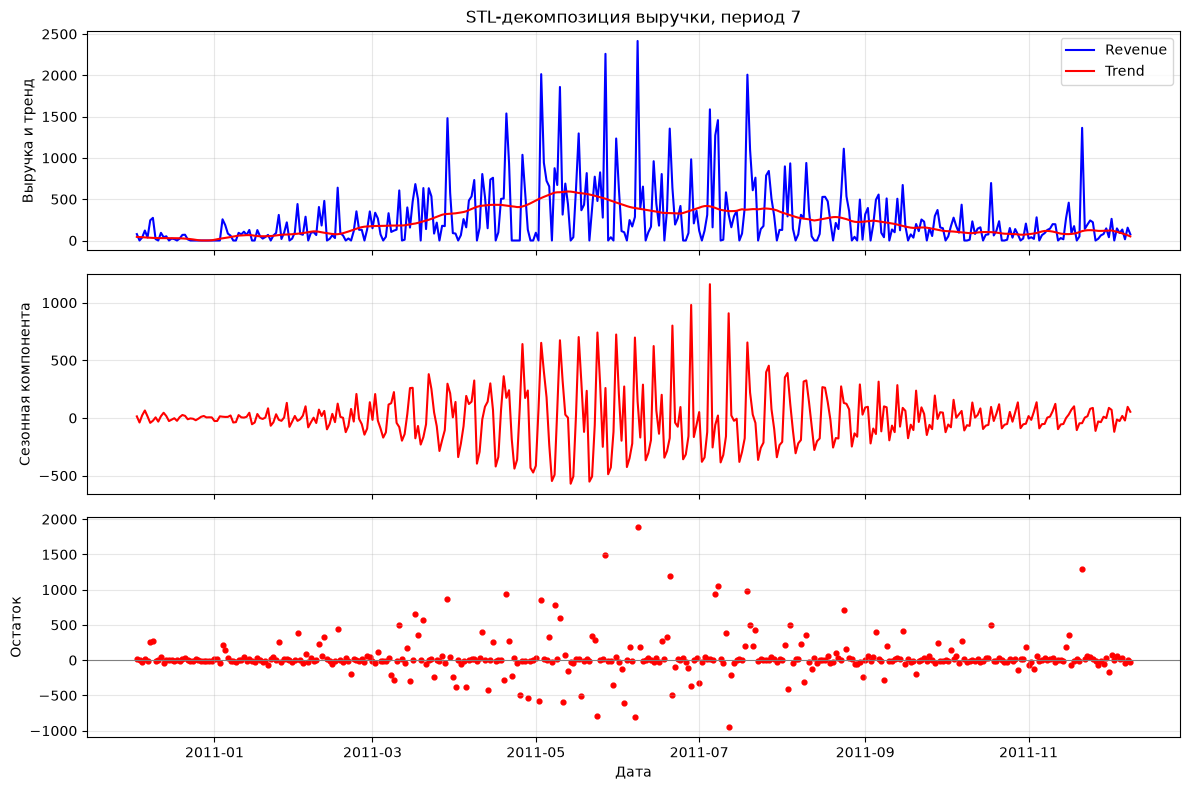

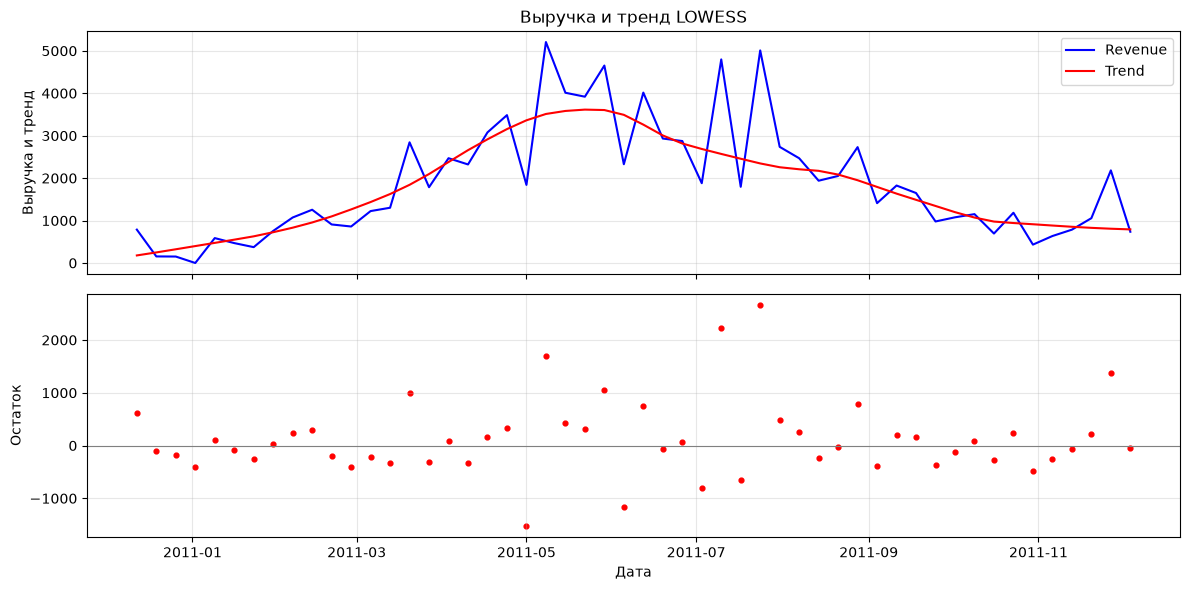

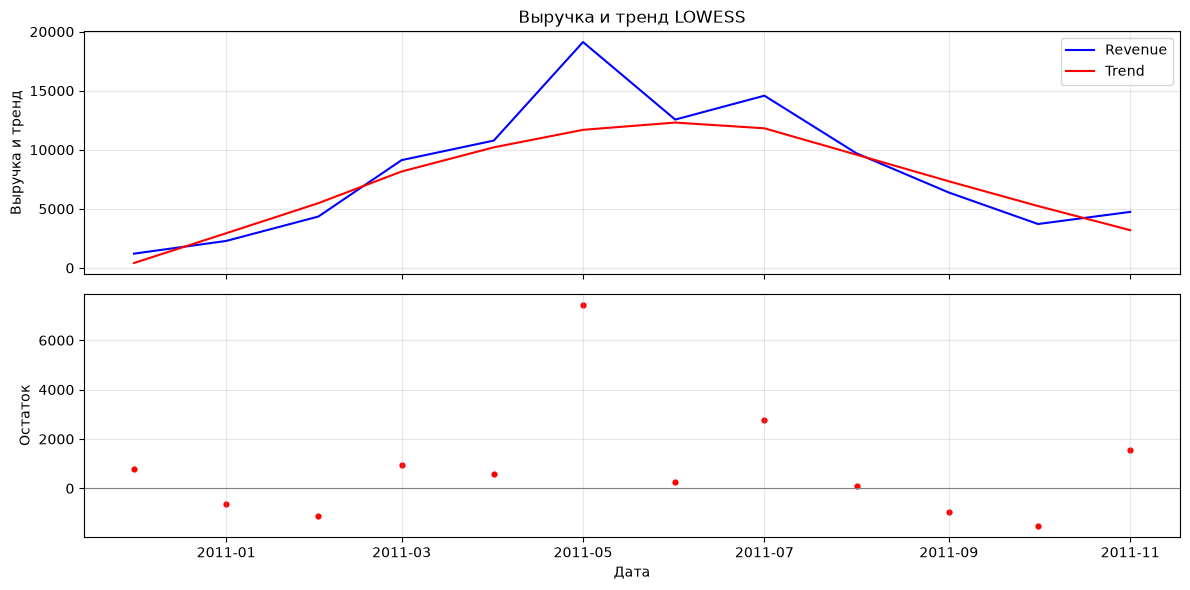

In [1118]:
daily_components   = decompose_stl   (d, period=7, robust=True, draw=True)
weekly_components  = decompose_lowess(w, frac=0.3, draw=True)
monthly_components = decompose_lowess(m, frac=0.6, draw=True)

### 4.3. Анализ компонент временного ряда

На всех трёх агрегациях заметен общий подъём выручки с последующим спадом. Недельная и месячная агрегации сглаживают дневные скачки и позволяют лучше увидеть эту динамику.

**Тренд.** На всех трёх агрегациях выручка растёт зимой и весной 2011 года, достигает высокого уровня в мае-июле и снижается к осени. Различия в положении максимума связаны с агрегацией и сглаживанием. Одного года наблюдений недостаточно, чтобы считать этот подъём и спад годовой сезонностью.

**Сезонность.** В дневном ряду STL выделил недельный рисунок. Амплитуда сезонных колебаний увеличивается весной и летом, затем уменьшается вместе с уровнем выручки. Для недельного и месячного рядов сезонную компоненту отдельно не выделяли, поскольку обоснованный период не установлен.

**Остатки.** Большинство дневных остатков близко к нулю, но встречаются крупные положительные всплески. Разброс заметно больше весной и летом. В недельном ряду также остаются сильные отклонения в мае-июле. В месячном ряду крупнейший положительный остаток приходится на май и составляет около 7,5 тыс. Называть остатки белым шумом оснований нет.

Дополнительно рассмотрим сезонную поправку по дням недели и ACF дневных и недельных остатков. Для месячного ряда из 12 наблюдений оценка ACF слишком неточна для уверенных выводов.

In [1119]:
def plot_seasonal_boxplot(seasonal):
    _, ax = plt.subplots(figsize=(8, 4))

    sns.boxplot(
        x=seasonal.index.dayofweek,
        y=seasonal,
        order=range(7),
        color="red",
        ax=ax,
    )

    ax.set_xticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title("Сезонность по дням недели")
    ax.set_xlabel("День недели")
    ax.set_ylabel("Сезонная поправка к выручке")

    plt.tight_layout()
    plt.show()


def plot_residual_acf(residuals, name: str):
    _, ax = plt.subplots(figsize=(8, 4))

    plot_acf(residuals, zero=False, ax=ax)
    ax.set_title(f"ACF остатков {name}")
    ax.set_xlabel("Лаг")
    ax.set_ylabel("ACF")

    plt.tight_layout()
    plt.show()

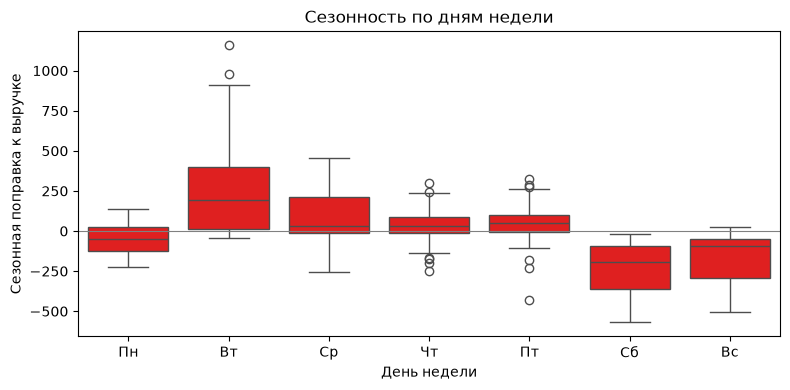

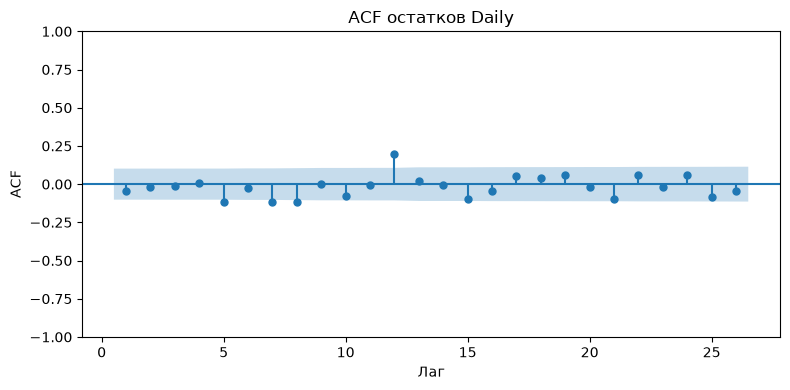

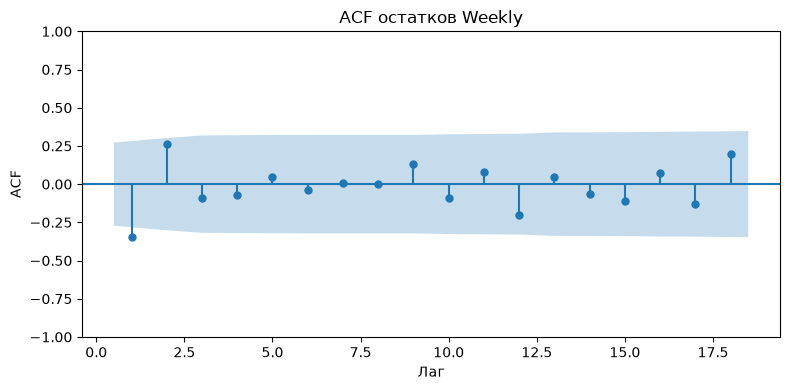

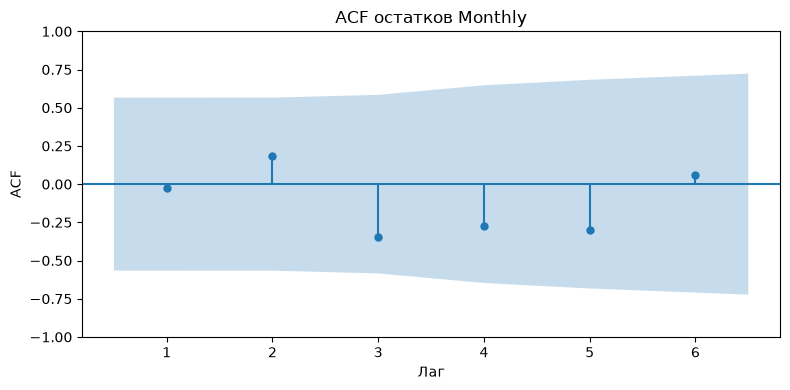

In [1120]:
plot_seasonal_boxplot(daily_components["S"])

plot_residual_acf(daily_components["R"],   name='Daily')
plot_residual_acf(weekly_components["R"],  name='Weekly')
plot_residual_acf(monthly_components["R"], name='Monthly')

Наибольшая положительная сезонная поправка приходится на вторник, отрицательная -- на субботу и воскресенье. Нулевая выручка по субботам объясняет часть недельного рисунка. Разброс поправок внутри каждого дня недели показывает, что их величина меняется в течение года.

После STL недельные пики ACF дневного ряда заметно ослабли. Это указывает на то, что разложение выделило основную часть недельной зависимости.

В ACF недельных остатков на первых лагах отрицательная корреляция сменяется положительной. После удаления тренда сохраняются признаки чередования отклонений, но сами по себе они не доказывают наличие сезонности.

### 4.4. Вывод о сезонности

В дневном ряду заметна недельная сезонность с периодом **7 дней**. На это указывают повторяющиеся пики ACF на лагах, кратных неделе. Сезонная поправка наиболее положительна во вторник и отрицательна в выходные. После STL недельные пики ACF остатков заметно ослабли, что дополнительно поддерживает этот вывод. При этом величина сезонных колебаний меняется: весной и летом они сильнее, осенью слабее.

Недельная и месячная агрегации сглаживают различия между днями недели. Убедительных признаков других сезонных периодов не обнаружено. Подъём и последующий спад выручки могут быть частью более длинного цикла, но данных примерно за год недостаточно, чтобы установить годовую сезонность.

## Шаг 5. Стационарность
---

### 5.1. Выбор метода оценки стационарности

| Метод | Что проверяем |
|---|---|
| Визуальный анализ | Меняются ли уровень и разброс ряда. Смотрим на сам ряд, скользящее среднее и стандартное отклонение. |
| ADF | Проверяет наличие единичного корня. Малое p-value позволяет отвергнуть эту гипотезу, но не доказывает стационарность во всех отношениях. |
| KPSS | Проверяет стационарность относительно постоянного уровня или линейного тренда. Малое p-value говорит против выбранной гипотезы стационарности. |

Сопоставим графики с результатами ADF и KPSS. У тестов противоположные нулевые гипотезы, поэтому они дополняют друг друга. 

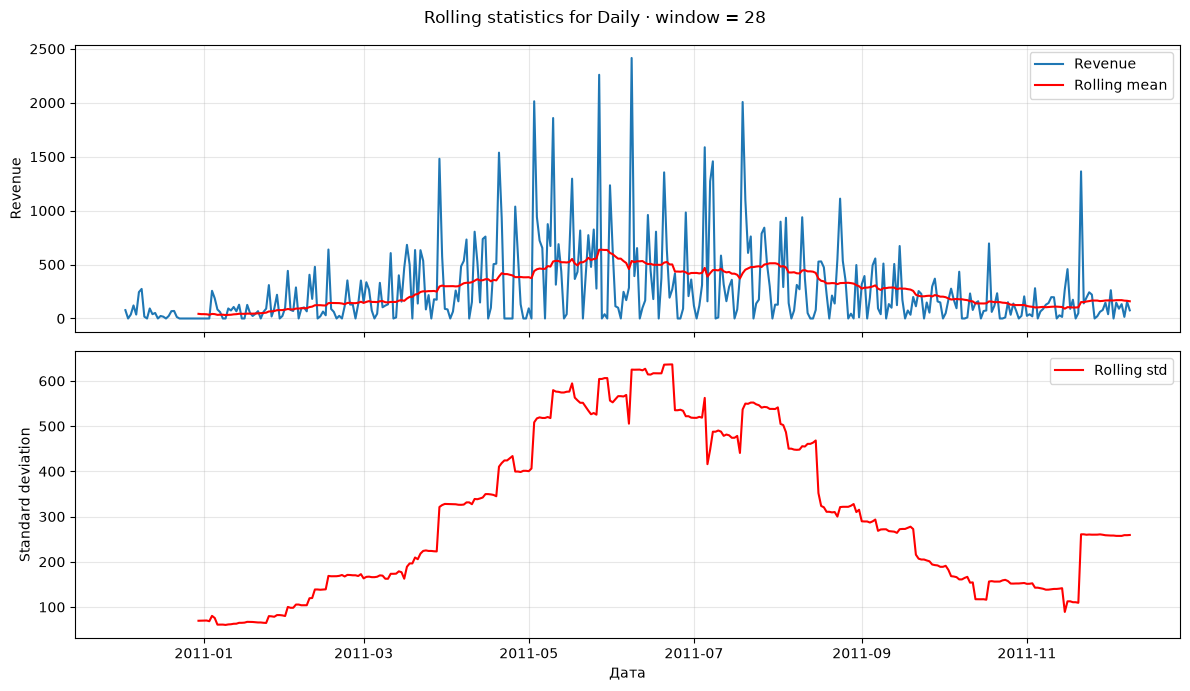

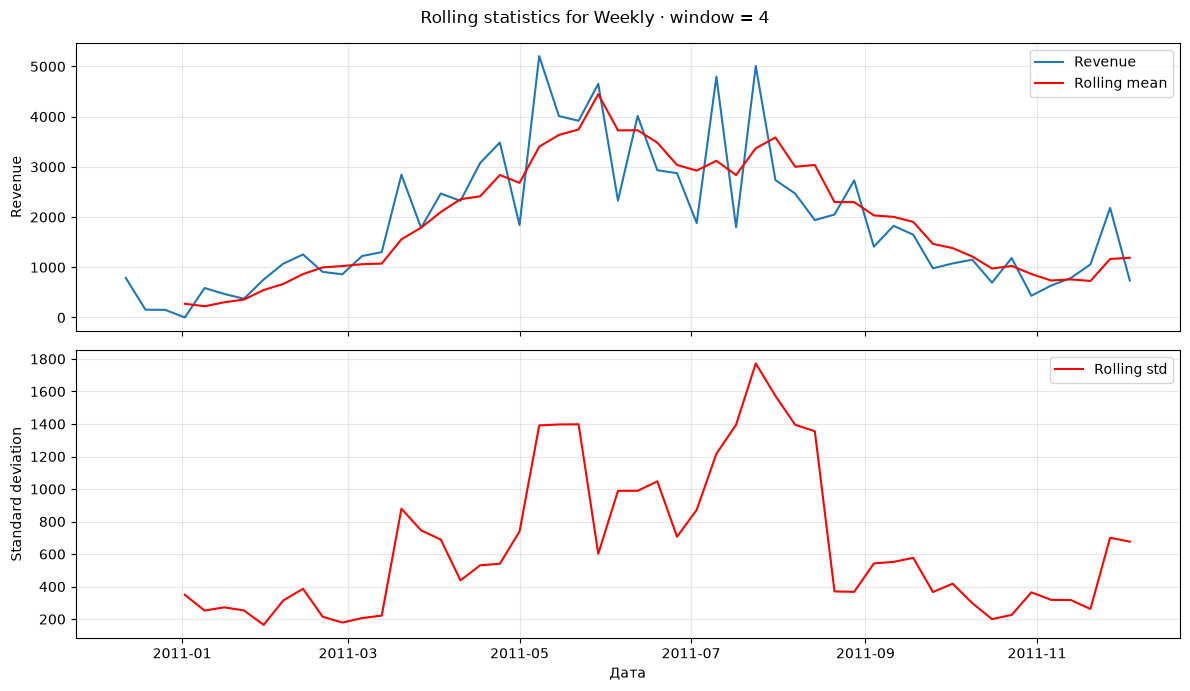

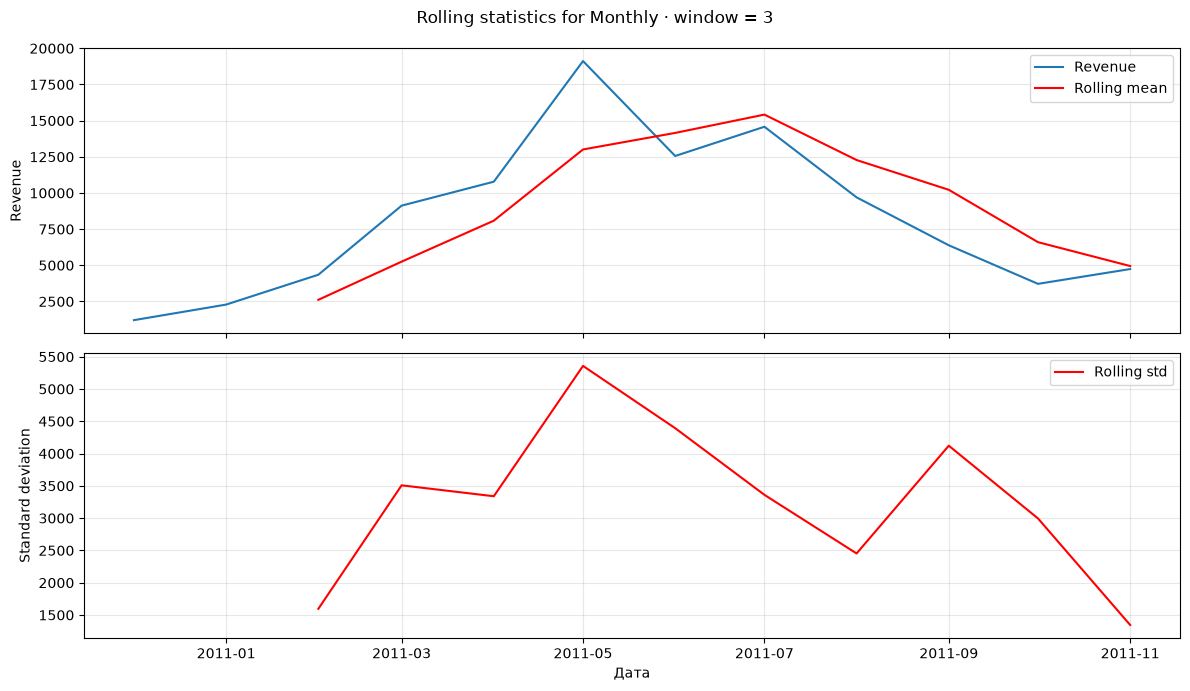

In [1121]:
plot_rolling(d, window=28, name='Daily')     # 28 дней
plot_rolling(w, window=4,  name='Weekly')    # 4 недели
plot_rolling(m, window=3,  name='Monthly')   # 3 месяца

Во всех трёх агрегациях видны рост выручки к середине периода и последующее снижение. Скользящее среднее также меняется со временем, что указывает на непостоянство уровня ряда.

Разброс выручки выше в период активных продаж и ниже в начале и конце ряда. Изменения скользящего стандартного отклонения указывают на непостоянство дисперсии.

Таким образом, визуальный анализ даёт основания предполагать нестационарность рядов. Проверим этот вывод с помощью ADF и KPSS.

### 5.2. Статистические тесты для оценки стационарности

#### 5.2.1. ADF

Используем расширенный тест Дики-Фуллера (ADF).

Нулевая гипотеза: в ряду есть единичный корень.

- При `p_value < 0.05` отвергаем эту гипотезу. Результат говорит в пользу стационарности, но не подтверждает все её условия.
- При `p_value ≥ 0.05` данных недостаточно, чтобы отвергнуть гипотезу единичного корня.

In [1122]:
def test_adf(series):
    """H0: в ряду есть единичный корень."""
    stat, p_value, *_ = adfuller(
        series, 
        regression="c", 
        autolag="AIC", 
        result_object=False
    )
    return pd.Series({
        "statistic": stat,
        "p_value":   p_value,
        "reject_H0": p_value < 0.05,
    })

In [1123]:
display(pd.DataFrame({
    "Daily":   test_adf(d["Revenue"]),
    "Weekly":  test_adf(w["Revenue"]),
    "Monthly": test_adf(m["Revenue"]),
}))

,Daily,Weekly,Monthly
statistic,-1.872932,-1.680521,-3.63476
p_value,0.3449,0.441175,0.00513
reject_H0,False,False,True


#### 5.2.1. KPSS

Используем тест KPSS.

Нулевая гипотеза: ряд стационарен относительно постоянного уровня.

- При `p_value < 0.05` отвергаем гипотезу стационарности.
- При `p_value ≥ 0.05` оснований отвергнуть её нет.

In [1124]:
def test_kpss(series):
    """H0: ряд стационарен относительно постоянного уровня."""
    stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
    return pd.Series({
        "statistic": stat,
        "p_value": p_value,
        "reject_H0": p_value < 0.05,
    })

In [1125]:
display(pd.DataFrame({
    "Daily":   test_kpss(d["Revenue"]),
    "Weekly":  test_kpss(w["Revenue"]),
    "Monthly": test_kpss(m["Revenue"]),
}))

/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)


,Daily,Weekly,Monthly
statistic,0.994732,0.274883,0.188876
p_value,0.01,0.1,0.1
reject_H0,True,False,False


Для дневной выручки результаты ADF и KPSS согласуются с нестационарностью, что соответствует видимым изменениям уровня и разброса.

Для недельной выручки вывод неоднозначен: ADF не отвергает гипотезу единичного корня, а KPSS не отвергает стационарность. С учётом заметного изменения уровня на графике считать ряд стационарным оснований недостаточно.

Для месячной выручки результаты говорят в пользу стационарности: ADF отвергает гипотезу единичного корня, а KPSS не отвергает стационарность. Но в ряду всего 12 наблюдений, и на графике заметны рост и последующее снижение. Этого недостаточно для уверенного вывода о стационарности.

### 5.3. Устранение нестационарности

Для устранения изменений уровня сперва попробуем первые разности: 
$$
\Delta y_t = y_t - y_{t-1}.
$$

In [1126]:
d_diff = d.diff().dropna()
w_diff = w.diff().dropna()
m_diff = m.diff().dropna()

### 5.4. Проверка после преобразования

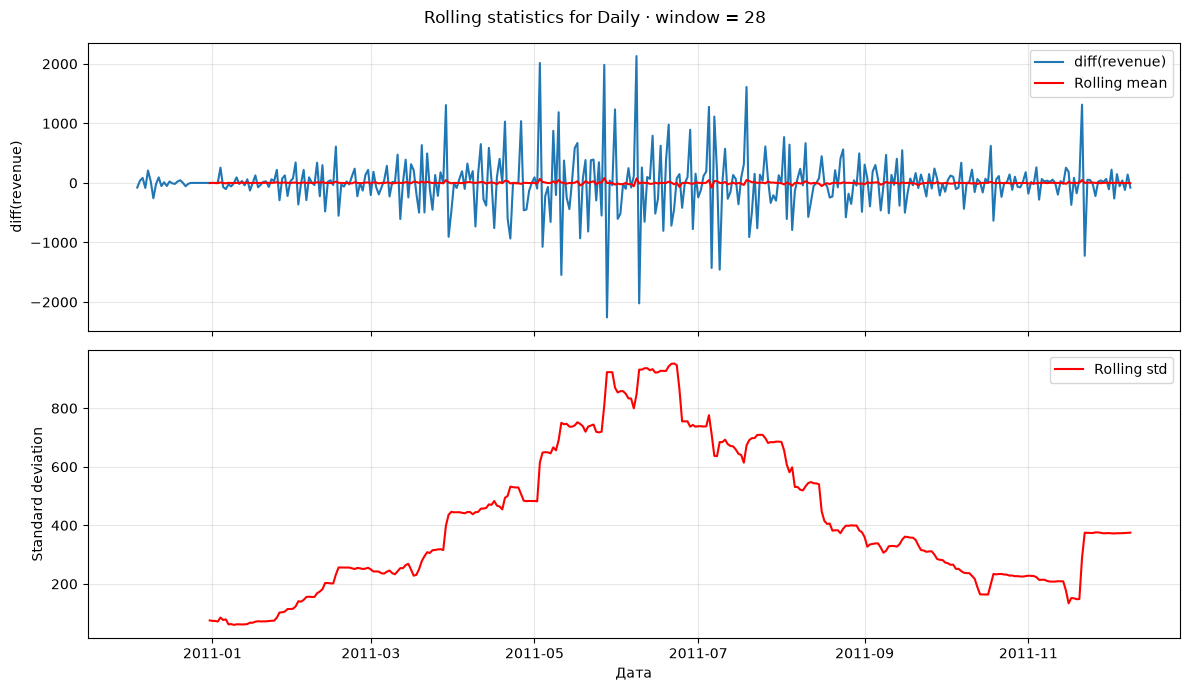

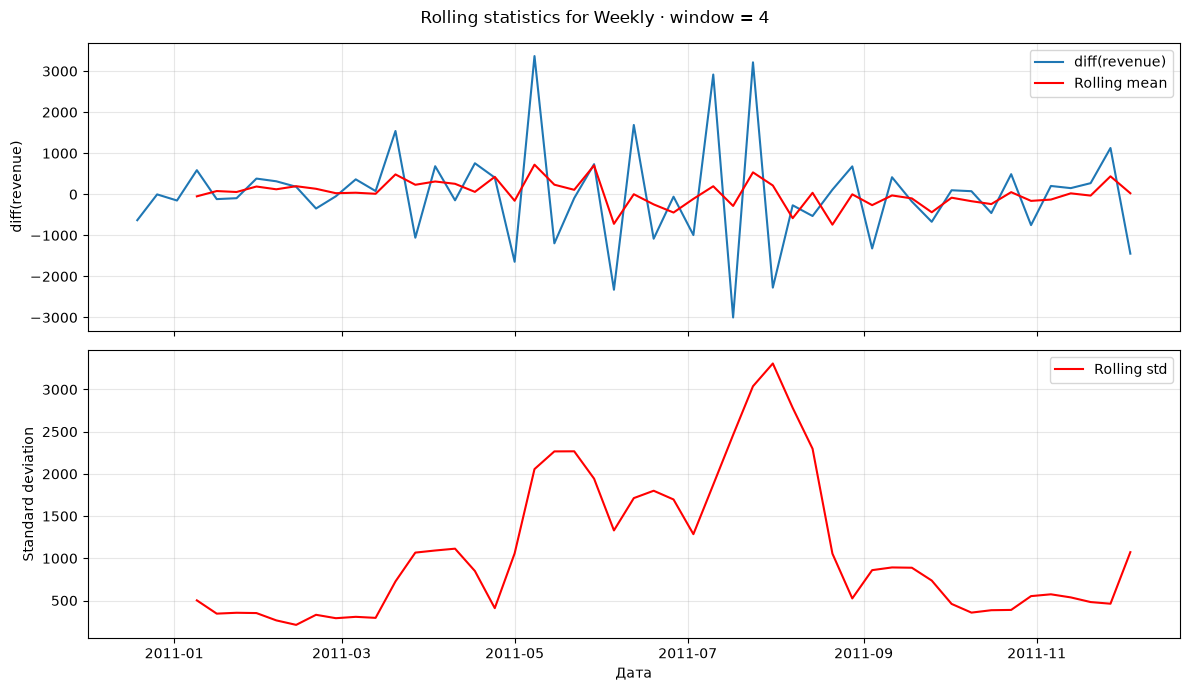

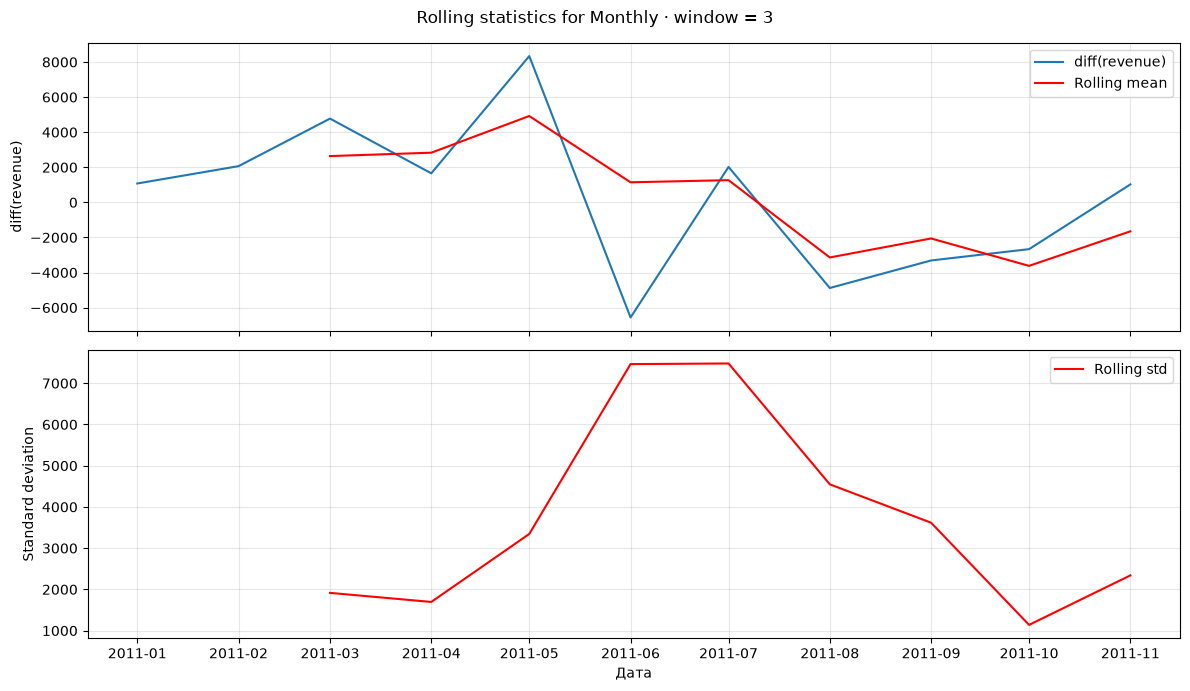

,Daily,Weekly,Monthly
statistic,-11.613883,-8.078502,-3.187053
p_value,0.0,0.0,0.020746
reject_H0,True,True,True


/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)


,Daily,Weekly,Monthly
statistic,0.242744,0.141616,0.349656
p_value,0.1,0.1,0.098855
reject_H0,False,False,False


In [1127]:
plot_rolling(d_diff, window=28, name='Daily',   ylabel='diff(revenue)')  # 28 дней
plot_rolling(w_diff, window=4,  name='Weekly',  ylabel='diff(revenue)')  # 4 недели
plot_rolling(m_diff, window=3,  name='Monthly', ylabel='diff(revenue)')  # 3 месяца

display(pd.DataFrame({
    "Daily":   test_adf(d_diff['Revenue']),
    "Weekly":  test_adf(w_diff['Revenue']),
    "Monthly": test_adf(m_diff['Revenue']),
}))

display(pd.DataFrame({
    "Daily":   test_kpss(d_diff['Revenue']),
    "Weekly":  test_kpss(w_diff['Revenue']),
    "Monthly": test_kpss(m_diff['Revenue']),
}))

#### Результаты после дифференцирования

У дневного и недельного рядов первые разности убрали выраженный рост и последующее снижение уровня. Скользящее среднее стало устойчивее и колеблется около нуля, но разброс остался неоднородным: в середине периода колебания сильнее, чем по краям.

У месячного ряда в первой части периода преобладают положительные изменения, во второй -- отрицательные. Скользящие среднее и стандартное отклонение заметно меняются. После преобразования осталось лишь 11 наблюдений, поэтому оценка стационарности ненадёжна.

| Агрегация | Исходный ряд | После дифференцирования |
|---|---|---|
| Дневная | Оба теста указывали на нестационарность | ADF отвергает единичный корень, KPSS не отвергает стационарность |
| Недельная | Тесты не давали однозначного ответа | ADF отвергает единичный корень, KPSS не отвергает стационарность |
| Месячная | Тесты поддерживали стационарность, но наблюдений мало | ADF отвергает единичный корень, KPSS не отвергает стационарность (при 11 наблюдениях вывод ненадёжен) |

На уровне значимости 0,05 результаты тестов согласуются со стационарностью преобразованных дневного и недельного рядов. Однако неоднородный разброс на графиках не позволяет считать стационарность установленной. Для месячного ряда польза дифференцирования неочевидна.

#### 5.4.1. Логарифмирование и первые разности

После дифференцирования уровень дневного и недельного рядов стал устойчивее, но разброс по-прежнему меняется. Попробуем сначала применить `log1p`, а затем взять первые разности. Логарифм сжимает большие значения и может сделать разброс более равномерным, а добавление единицы позволяет сохранить дни с нулевой выручкой.

In [1128]:
d_log_diff = np.log1p(d).diff().dropna()
w_log_diff = np.log1p(w).diff().dropna()
m_log_diff = np.log1p(m).diff().dropna()

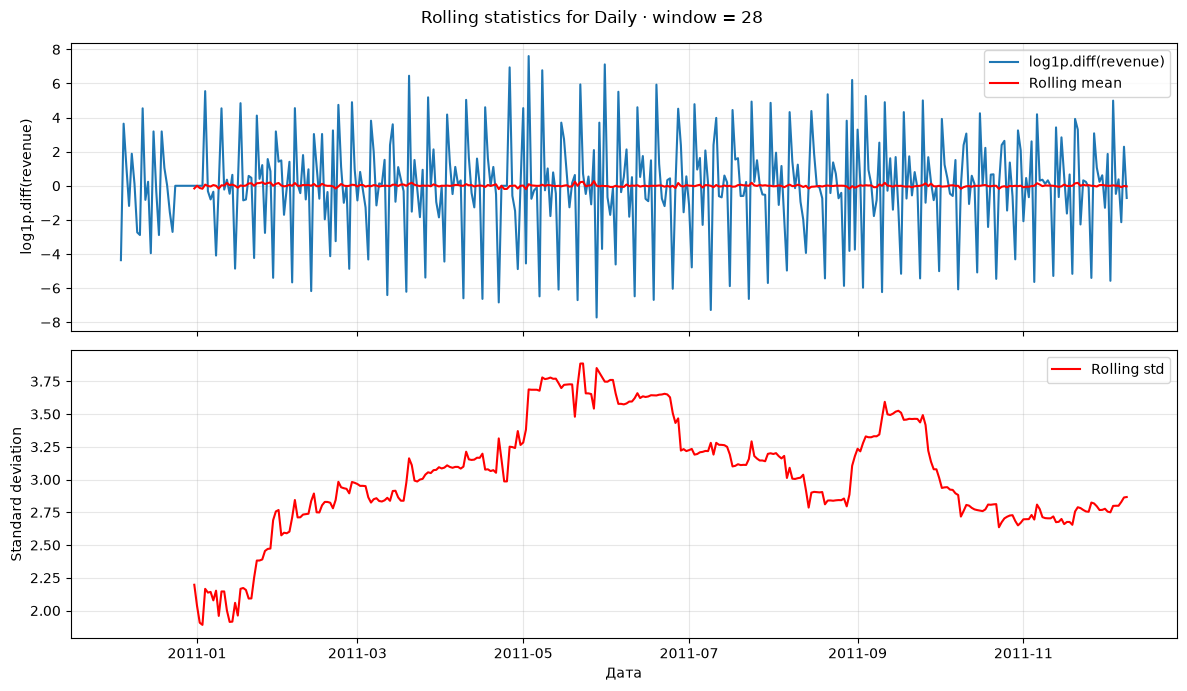

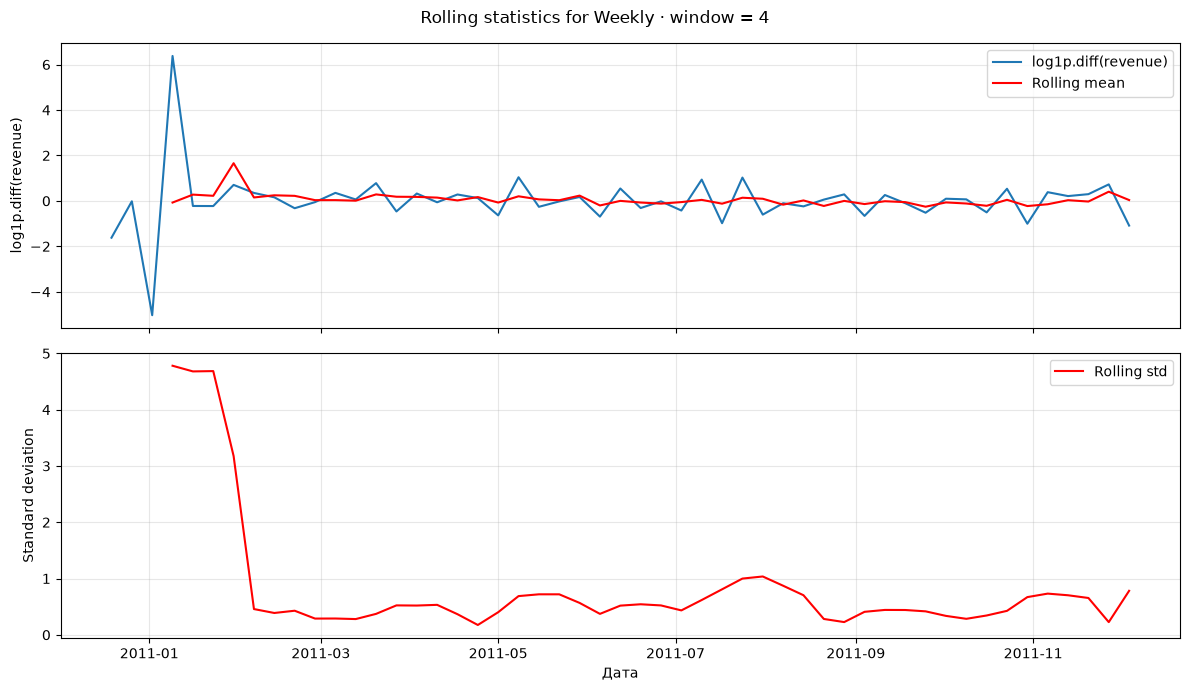

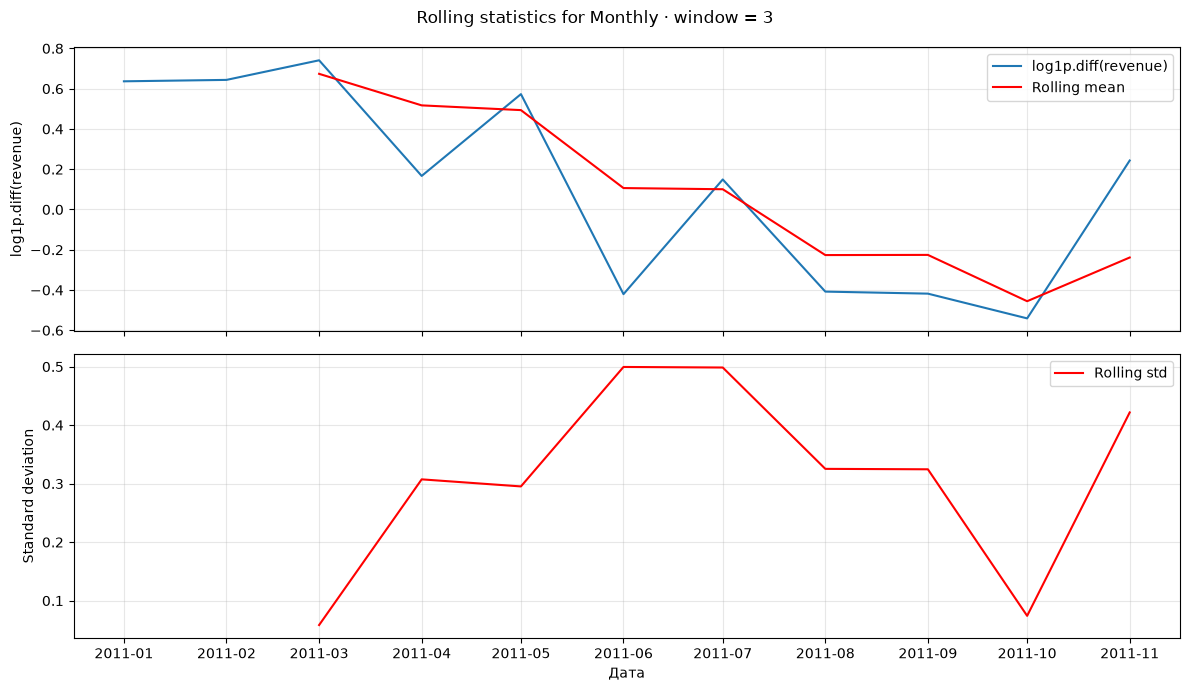

,Daily,Weekly,Monthly
statistic,-10.353216,-12.227521,-1.177899
p_value,0.0,0.0,0.68303
reject_H0,True,True,False


/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)


,Daily,Weekly,Monthly
statistic,0.174613,0.10676,0.488585
p_value,0.1,0.1,0.044238
reject_H0,False,False,True


In [1129]:
plot_rolling(d_log_diff, window=28, name='Daily',   ylabel='log1p.diff(revenue)')  # 28 дней
plot_rolling(w_log_diff, window=4,  name='Weekly',  ylabel='log1p.diff(revenue)')  # 4 недели
plot_rolling(m_log_diff, window=3,  name='Monthly', ylabel='log1p.diff(revenue)')  # 3 месяца

display(pd.DataFrame({
    "Daily":   test_adf(d_log_diff['Revenue']),
    "Weekly":  test_adf(w_log_diff['Revenue']),
    "Monthly": test_adf(m_log_diff['Revenue']),
}))

display(pd.DataFrame({
    "Daily":   test_kpss(d_log_diff['Revenue']),
    "Weekly":  test_kpss(w_log_diff['Revenue']),
    "Monthly": test_kpss(m_log_diff['Revenue']),
}))

Проверим также, сохранился ли недельный рисунок после логарифмирования и первых разностей. Для этого рассмотрим ACF и распределение преобразованной выручки по дням недели.

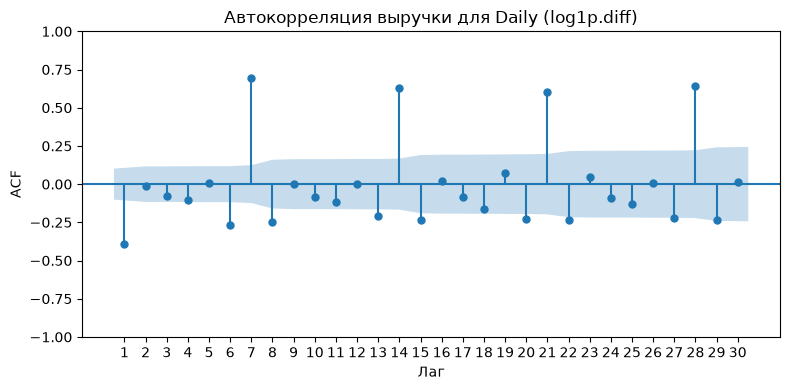

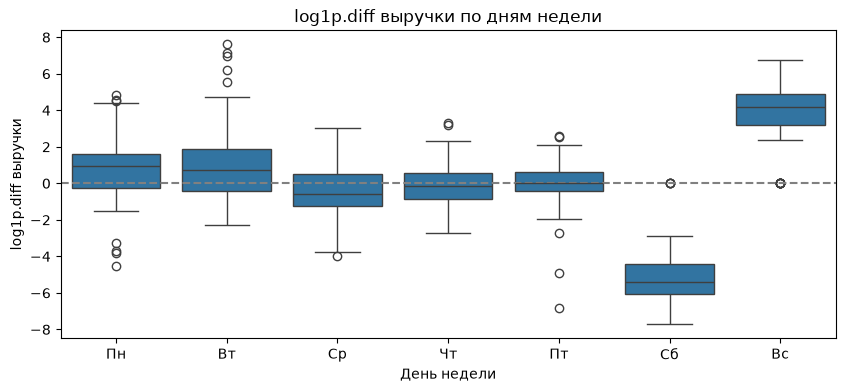

,mean,median,std
День недели,,,
Пн,0.754,0.934,2.016
Вт,1.223,0.726,2.247
Ср,-0.421,-0.562,1.409
Чт,-0.071,-0.131,1.276
Пт,-0.082,0.000,1.566
Сб,-5.032,-5.404,1.754
Вс,3.628,4.180,1.883


In [1130]:
# Автокорреляция преобразованного дневного ряда
plot_revenue_acf(
    d_log_diff,
    lags=30,
    name="Daily (log1p.diff)",
)

# Различия между днями недели
def weekly_boxplot(df_agg, type: str, feature='Revenue'):
    revenue = df_agg[feature]
    weekdays = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

    _, ax = plt.subplots(figsize=(10, 4))
    sns.boxplot(
        x=revenue.index.dayofweek,
        y=revenue,
        order=range(7),
        ax=ax,
    )
    ax.set_xticks(range(7), weekdays)
    ax.axhline(0, color="gray", linestyle="--")
    ax.set(
        title=f"{type} выручки по дням недели",
        xlabel="День недели",
        ylabel=f"{type} выручки",
    )
    plt.show()

    stats = (
        revenue.groupby(revenue.index.dayofweek)
        .agg(["mean", "median", "std"])
        .reindex(range(7))
    )
    stats.index = pd.Index(weekdays, name="День недели")
    display(stats.round(3))

weekly_boxplot(d_log_diff, type='log1p.diff')

Посмотрим еще на это же преобразование, но с сезонной разностью для дневной агрегации

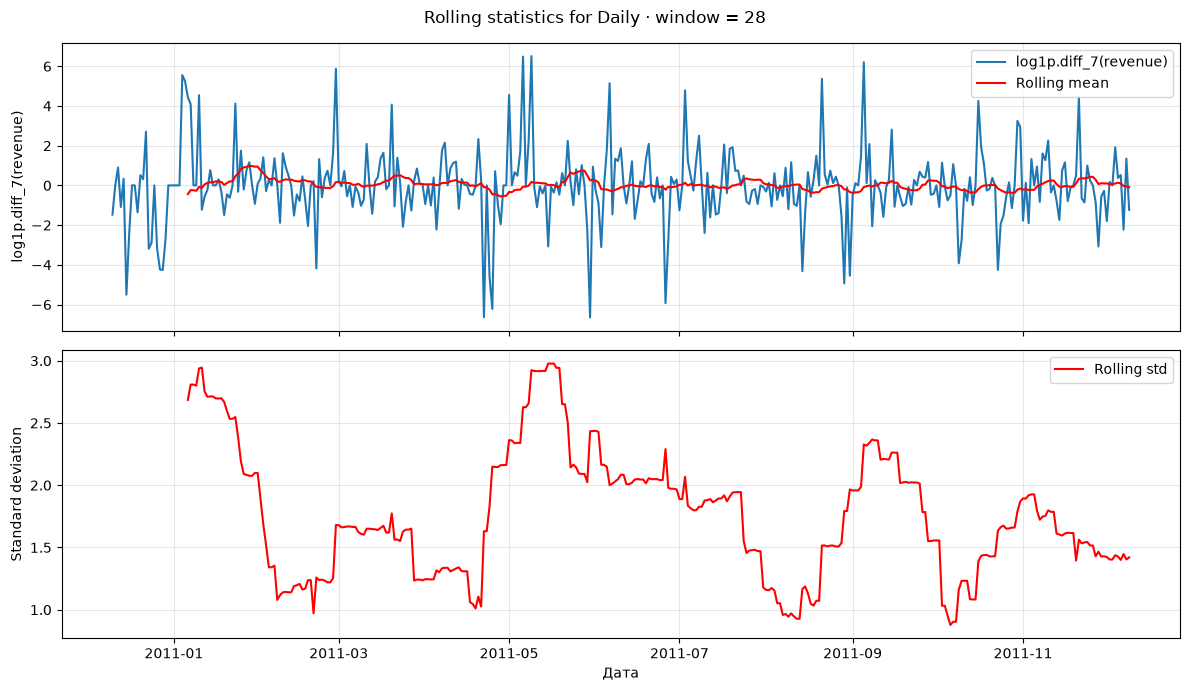

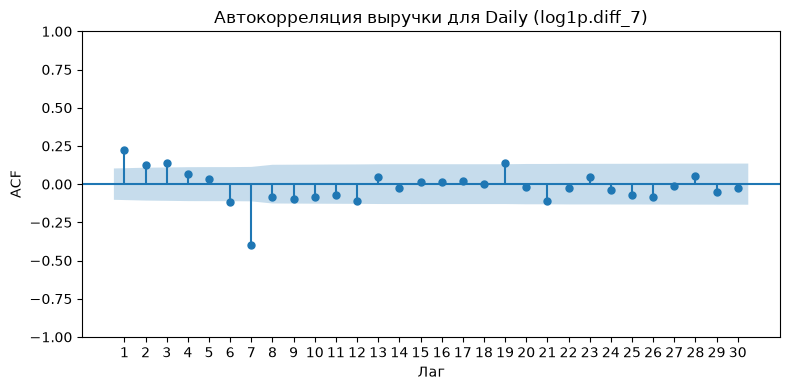

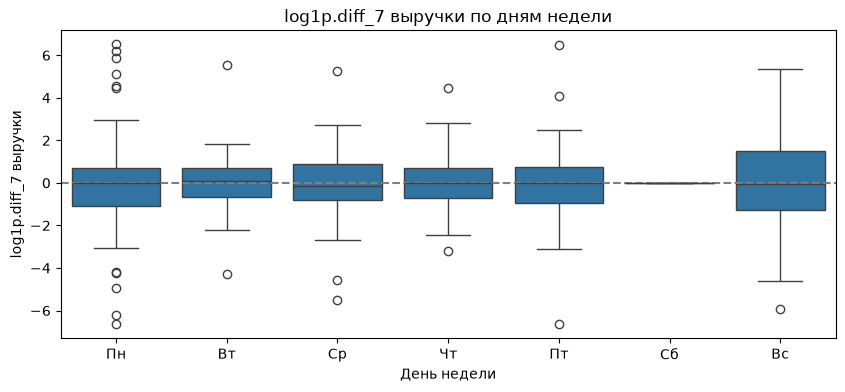

,mean,median,std
День недели,,,
Пн,-0.005,0.000,2.763
Вт,0.025,0.078,1.380
Ср,-0.053,-0.131,1.670
Чт,-0.011,-0.023,1.364
Пт,-0.000,0.000,1.811
Сб,0.000,0.000,0.000
Вс,0.026,-0.037,2.521


In [1131]:
d_log_seasonal_diff = np.log1p(d).diff(7).dropna()

plot_rolling(
    d_log_seasonal_diff, 
    window=28, 
    name='Daily',
    ylabel="log1p.diff_7(revenue)")  # 28 дней

plot_revenue_acf(
    d_log_seasonal_diff,
    lags=30,
    name="Daily (log1p.diff_7)",
)

weekly_boxplot(d_log_seasonal_diff, type='log1p.diff_7')

In [1132]:
display(pd.DataFrame({
    "diff(1)": test_adf(d_log_diff["Revenue"]),
    "diff(7)": test_adf(d_log_seasonal_diff["Revenue"]),
}))

display(pd.DataFrame({
    "diff(1)": test_kpss(d_log_diff["Revenue"]),
    "diff(7)": test_kpss(d_log_seasonal_diff["Revenue"]),
}))

,diff(1),diff(7)
statistic,-10.353216,-6.533067
p_value,0.0,0.0
reject_H0,True,True


/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)
/tmp/ipykernel_8630/709160408.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  stat, p_value, *_ = kpss(series, regression="c", nlags="auto", result_object=False,)


,diff(1),diff(7)
statistic,0.174613,0.026628
p_value,0.1,0.1
reject_H0,False,False


После сезонного дифференцирования с лагом 7 средние значения по дням недели приблизились к нулю, а повторяющиеся положительные пики ACF исчезли. Однако разброс остаётся неоднородным: субботние значения равны нулю, а скользящее стандартное отклонение заметно меняется во времени. Преобразование устранило выраженные недельные различия среднего уровня, но не все признаки нестационарности.

#### Результаты после логарифмирования и дифференцирования

У дневного ряда скользящее среднее остаётся около нуля. По сравнению с обычными разностями разброс стал более равномерным, хотя в середине периода колебания всё ещё сильнее. ADF отвергает единичный корень, а KPSS не отвергает стационарность.

У недельного ряда также заметно уменьшились различия в разбросе. Выделяются резкие скачки в начале периода, но далее среднее близко к нулю, а стандартное отклонение меняется умеренно. Оба теста дают результаты в пользу стационарности.

У месячного ряда после логарифмирования и первых разностей скользящее среднее продолжает меняться, а разброс остаётся неоднородным. ADF не отвергает гипотезу единичного корня, а KPSS отвергает стационарность. Результаты согласуются с нестационарностью преобразованного ряда. При этом у нас мало наблюдений: после преобразования осталось всего 11, так что выводы считаем предварительными.

### 5.5. Требуется ли преобразование

Для дневной агрегации выбираем `log1p` с сезонной разностью лага 7: это преобразование уменьшило выраженные различия среднего уровня по дням недели. Неоднородность разброса при этом сохраняется.

Для недельной агрегации оставляем `log1p` с первыми разностями: изменения уровня и разброса уменьшились, а результаты ADF и KPSS согласуются со стационарностью.

Месячный ряд сохраняем исходным. Преимущество рассмотренных преобразований не подтверждено, а малого числа наблюдений недостаточно для надёжного вывода о стационарности.

In [1133]:
d = d_log_seasonal_diff
w = w_log_diff
m = m

## Шаг 6. Оформление методов анализа в класс
---

### 6.1. Вынесение используемых методов анализа и предобработки в класс

Вынесем основные методы в класс `SalesAnalysis` из файла `sales_analysis.py`. Создадим отдельный объект для каждой агрегации: дневной, недельной и месячной. Товар оставляем тот же, `PARTY BUNTING`.

Начинаем с исходной таблицы `df_raw`. Класс применяет очистку из шага 2 и считает количество продаж, выручку и число заказов. Для недельной и месячной агрегаций исключаем неполные периоды на границах датасета, как в шаге 3. Дни без записей считаем днями без продаж согласно принятому выше допущению.

In [1134]:
from sales_analysis import SalesAnalysis

### 6.2. Демонстрация работы

#### 6.2.1. Подготовка рядов

In [1135]:
analyses = {
    "Daily":   SalesAnalysis(df_raw, P_STOCKCODE, frequency="D"),
    "Weekly":  SalesAnalysis(df_raw, P_STOCKCODE, frequency="W-SUN"),
    "Monthly": SalesAnalysis(df_raw, P_STOCKCODE, frequency="MS"),
}

for name, analysis in analyses.items():
    print(name)
    display(analysis.aggregated.head())

display(pd.DataFrame({
    name: analysis.describe() for name, analysis in analyses.items()
}).round(3))

Daily


,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-03,11,77.47,4
2010-12-04,0,0.00,0
2010-12-05,8,37.20,3
2010-12-06,17,121.07,3
2010-12-07,4,36.43,3


Weekly


,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-12,165,786.34,19
2010-12-19,29,154.80,10
2010-12-26,24,151.93,12
2011-01-02,0,0.00,0
2011-01-09,145,586.71,9


Monthly


,Quantity,Revenue,InvoiceNo
InvoiceDate,,,
2010-12-01,237,1207.74,48
2011-01-01,485,2283.71,61
2011-02-01,925,4347.90,79
2011-03-01,1666,9123.02,157
2011-04-01,1937,10778.47,193


,Daily,Weekly,Monthly
count,372.000,52.000,1.200000e+01
mean,267.326,1901.164,8.210562e+03
std,375.778,1348.068,5.416097e+03
min,0.000,0.000,1.207740e+03
25%,23.250,841.428,4.190045e+03
50%,128.325,1717.205,7.753085e+03
75%,362.588,2731.978,1.122288e+04
max,2415.190,5206.440,1.911805e+04
variance,141208.901,1817286.073,2.933411e+07
range,2415.190,5206.440,1.791031e+04


#### 6.2.2. Уровень, разброс и сезонность

Посмотрим на ряды, скользящие статистики и ACF для всех частот. Окна оставляем прежними: 28 дней, 4 недели и 3 месяца.

Дневную выручку разложим методом STL с периодом 7. Для недельной и месячной оценим тренд через LOWESS с `frac=0.3` и `frac=0.6`. Сезонную компоненту для них не выделяем, поскольку устойчивого периода не обнаружили.

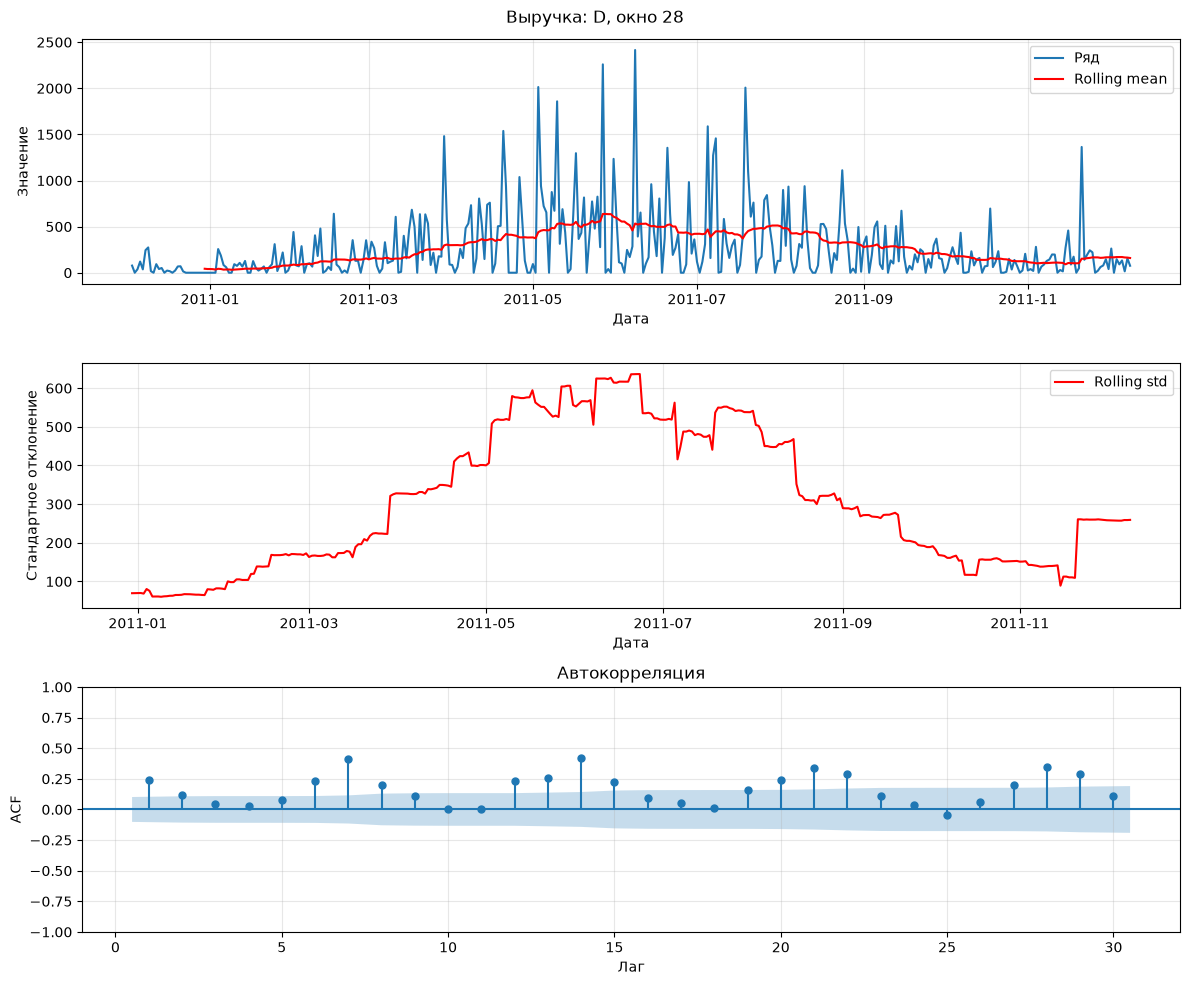

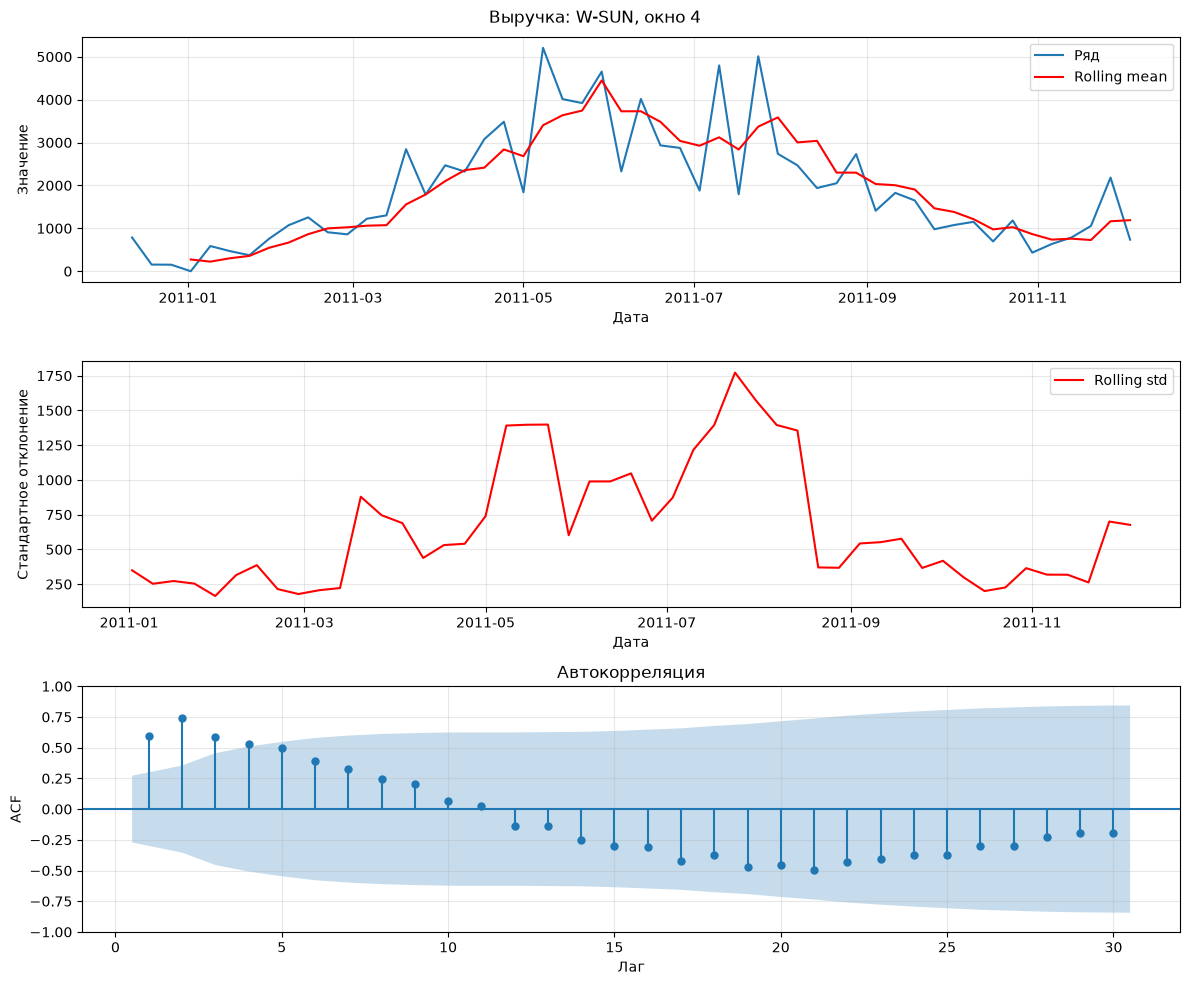

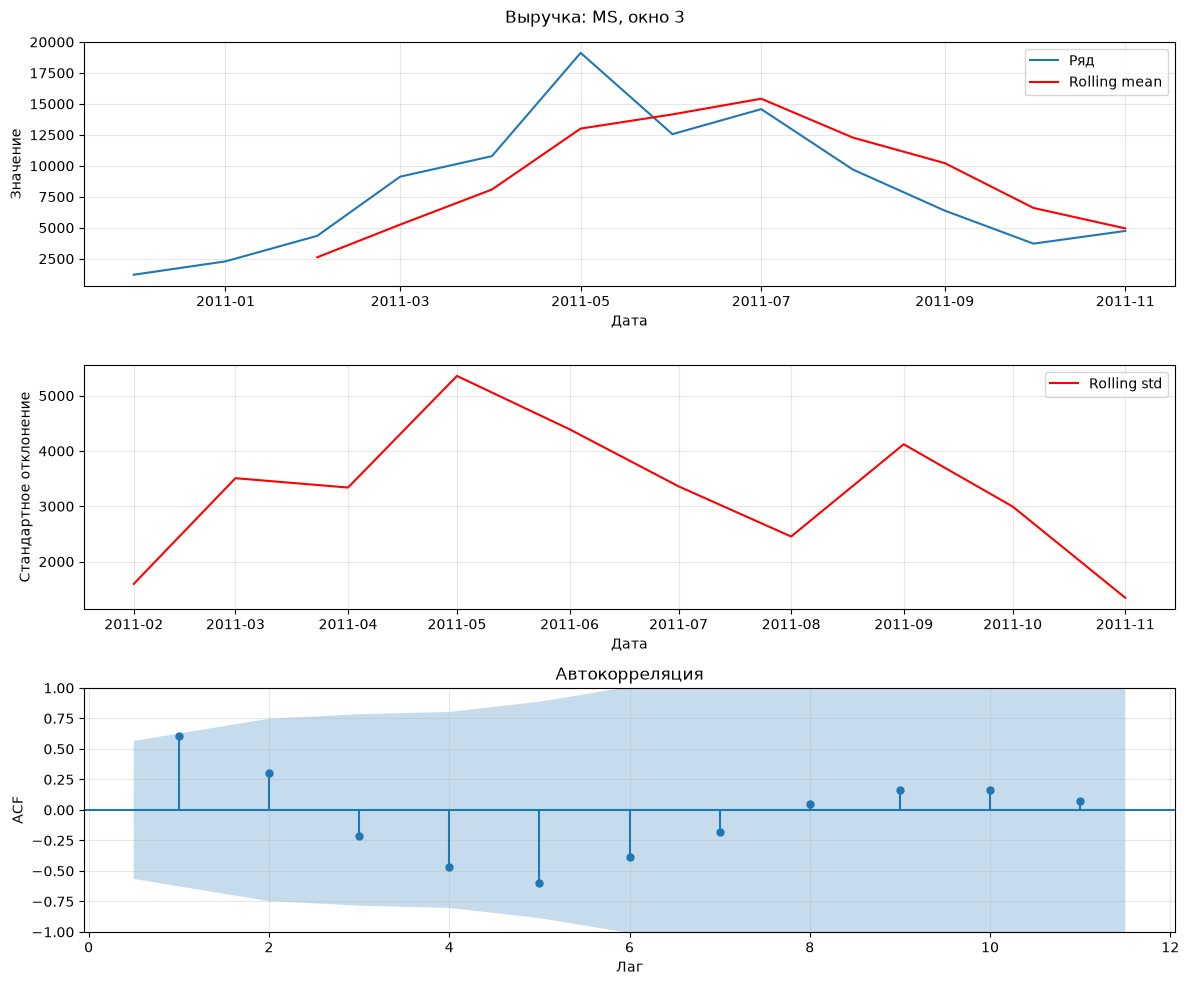

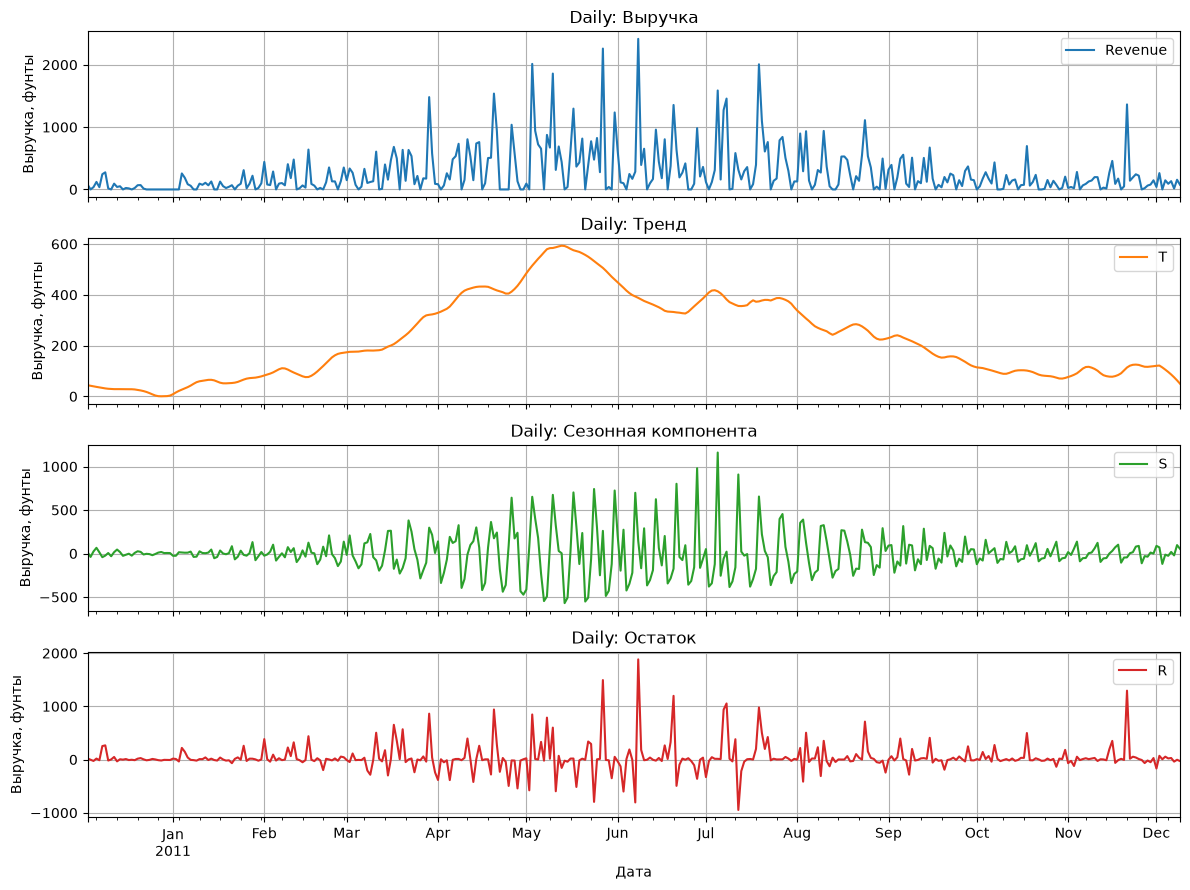

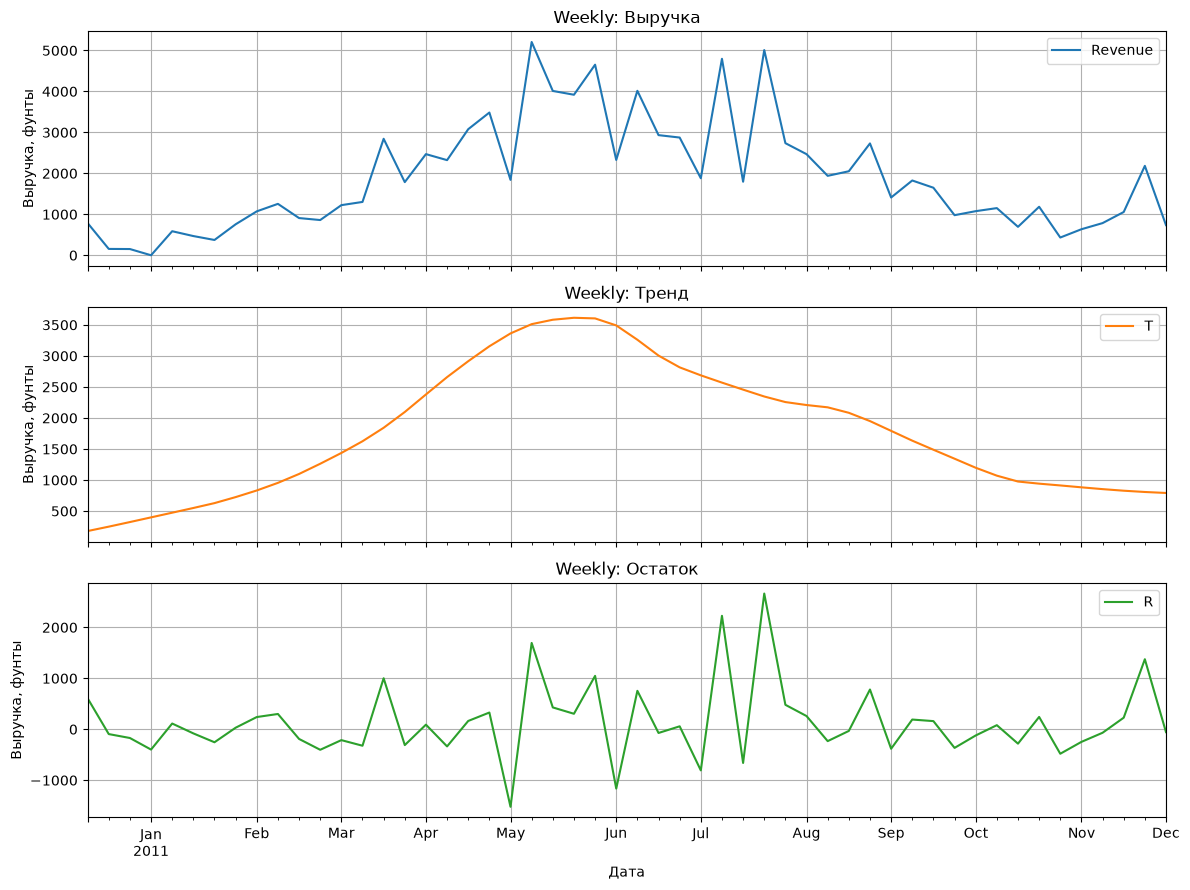

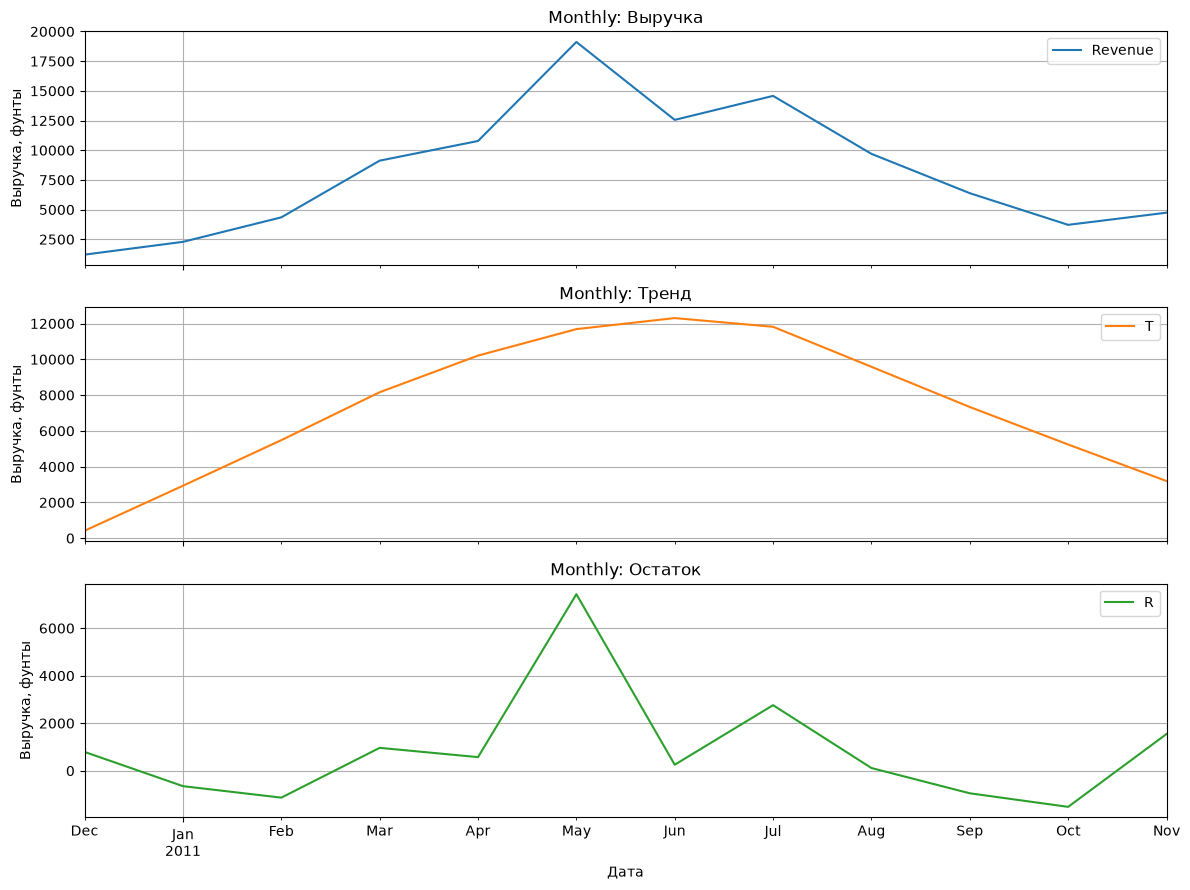

In [1136]:
windows = {"Daily": 28, "Weekly": 4, "Monthly": 3}

for name, analysis in analyses.items():
    analysis.plot_diagnostics(window=windows[name])

components = {
    "Daily":   analyses["Daily"].decompose_stl(period=7),
    "Weekly":  analyses["Weekly"].decompose_lowess(frac=0.3),
    "Monthly": analyses["Monthly"].decompose_lowess(frac=0.6),
}

component_names = {
    "Revenue": "Выручка",
    "T":       "Тренд",
    "S":       "Сезонная компонента",
    "R":       "Остаток",
}
for name, frame in components.items():
    axes = frame.plot(
        subplots=True,
        figsize=(12, 9),
        title=[f"{name}: {component_names[col]}" for col in frame.columns],
        grid=True,
    )

    for ax in axes:
        ax.set_ylabel("Выручка, фунты")

    axes[-1].set_xlabel("Дата")
    plt.tight_layout()

    plt.show()

#### 6.2.3. Преобразования и проверка стационарности

Для каждой агрегации сравним исходный ряд, первые разности и `log1p` с первыми разностями. Для дневной также проверим сезонную разность лага 7 после `log1p`.

У ADF нулевая гипотеза о наличии единичного корня, у KPSS о стационарности относительно постоянного уровня. Поэтому `reject_H0=True` для этих тестов имеет разный смысл.

Итоговый выбор оставляем из шага 5: для дневного ряда `log1p.diff(7)`, для недельного `log1p.diff(1)`. Месячный сохраняем исходным: преимуществ преобразования не увидели, а наблюдений слишком мало для уверенных выводов.

/home/nikita91/Documents/VScodeProjects/HSE/time-series/hw1/sales_analysis.py:133: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p, *_ = kpss(
/home/nikita91/Documents/VScodeProjects/HSE/time-series/hw1/sales_analysis.py:133: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, *_ = kpss(
/home/nikita91/Documents/VScodeProjects/HSE/time-series/hw1/sales_analysis.py:133: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, *_ = kpss(
/home/nikita91/Documents/VScodeProjects/HSE/time-series/hw1/sales_analysis.py:133: InterpolationWarning: The test statistic is outside of the range of p-valu

statistic  p_value  reject_H0
Агрегация Преобразование Тест                               
Daily     Исходный ряд   ADF     -1.8729   0.3449      False
                         KPSS     0.9947   0.0100       True
          diff(1)        ADF    -11.6139   0.0000       True
                         KPSS     0.2427   0.1000      False
          log1p.diff(1)  ADF    -10.3532   0.0000       True
                         KPSS     0.1746   0.1000      False
          log1p.diff(7)  ADF     -6.5331   0.0000       True
                         KPSS     0.0266   0.1000      False
Weekly    Исходный ряд   ADF     -1.6805   0.4412      False
                         KPSS     0.2749   0.1000      False
          diff(1)        ADF     -8.0785   0.0000       True
                         KPSS     0.1416   0.1000      False
          log1p.diff(1)  ADF    -12.2275   0.0000       True
                         KPSS     0.1068   0.1000      False
Monthly   Исходный ряд   ADF     -3.6348   0.0051       True
                         KPSS     0.1889   0.1000      False
          diff(1)        ADF     -3.1871   0.0207       True
                         KPSS     0.3497   0.0989      False
          log1p.diff(1)  ADF     -1.1779   0.6830      False
                         KPSS     0.4886   0.0442       True

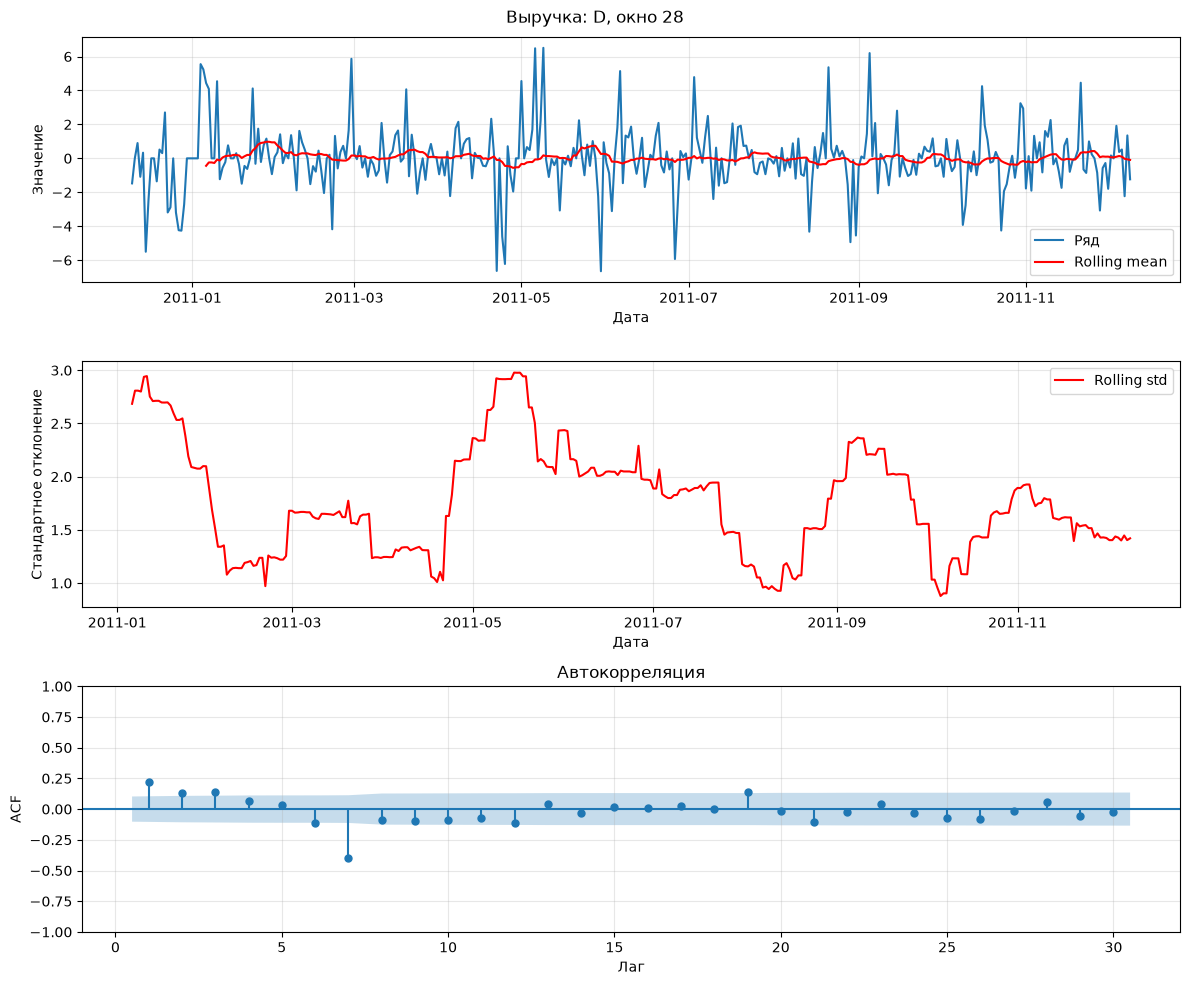

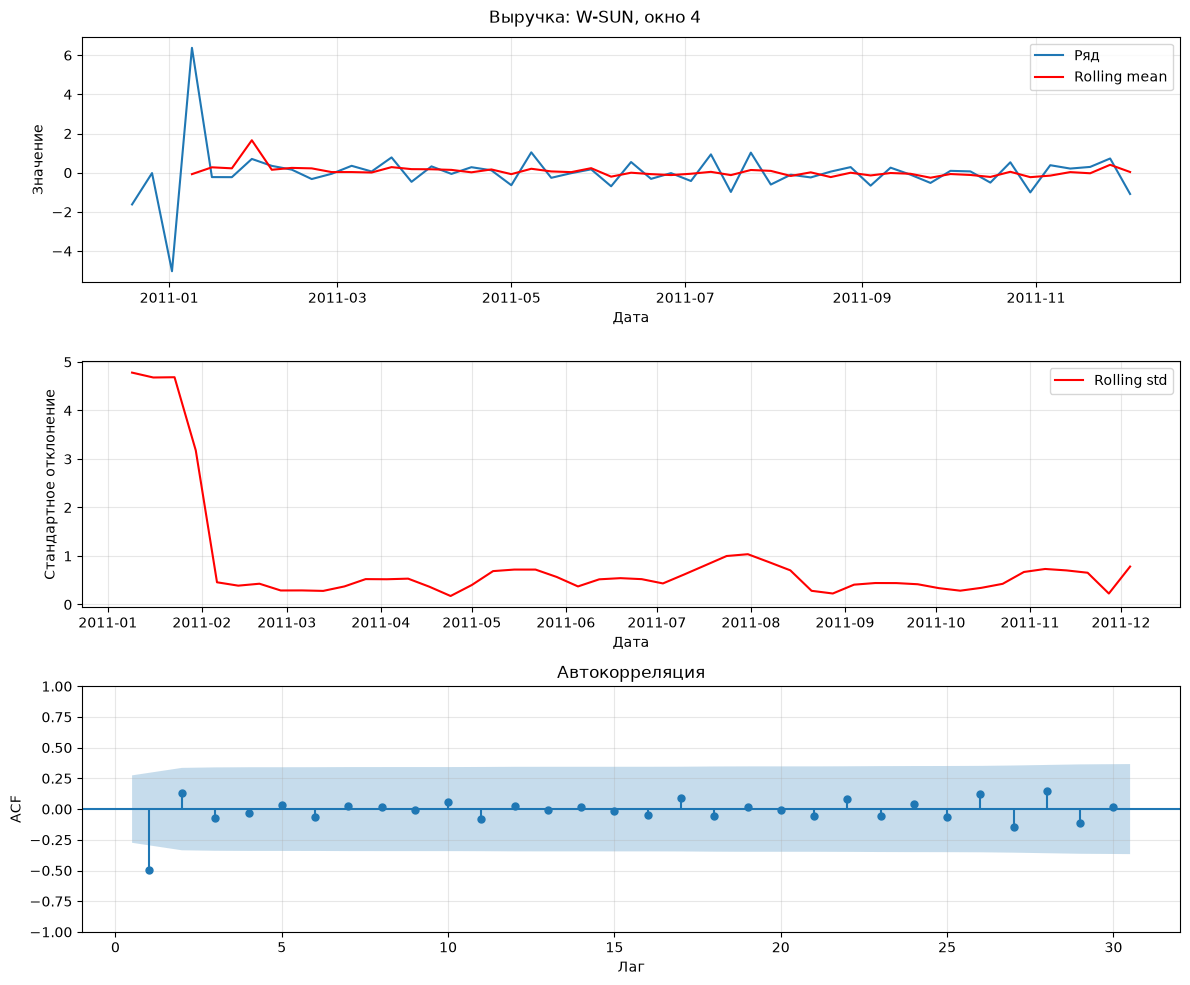

In [1137]:
stationarity_tables = {}

for name, analysis in analyses.items():
    variants = {
        "Исходный ряд":  analysis.revenue,
        "diff(1)":       analysis.difference(),
        "log1p.diff(1)": analysis.difference(log=True),
    }
    if name == "Daily":
        variants["log1p.diff(7)"] = analysis.difference(lag=7, log=True)

    stationarity_tables[name] = pd.concat({
        label: analysis.stationarity(series) for label, series in variants.items()
    }, names=["Преобразование"])

stationarity_results = pd.concat(stationarity_tables, names=["Агрегация"])
display(stationarity_results.round(4))

final_series = {
    "Daily":   analyses["Daily"].difference(lag=7, log=True),
    "Weekly":  analyses["Weekly"].difference(log=True),
    "Monthly": analyses["Monthly"].revenue,
}

# Для месячной агрегации график исходного ряда уже построен выше
for name in ["Daily", "Weekly"]:
    analyses[name].plot_diagnostics(final_series[name], window=windows[name])

### 6.3. Проверка воспроизводимости

Сравним агрегации и компоненты с расчётами выше. Проверим также итоговые преобразования и восстановление выручки из компонент. При последовательном запуске ноутбука все проверки должны пройти.

In [1138]:
expected_aggregations = aggregate(df, P_STOCKCODE, aggregation_rule)
expected_aggregations["weekly"]  = expected_aggregations["weekly"].iloc[1:-1]
expected_aggregations["monthly"] = expected_aggregations["monthly"].iloc[:-1]

expected_components = {
    "Daily":   daily_components,
    "Weekly":  weekly_components,
    "Monthly": monthly_components,
}
expected_series = {
    "Daily":   d_log_seasonal_diff["Revenue"],
    "Weekly":  w_log_diff["Revenue"],
    "Monthly": m["Revenue"],
}

for name, analysis in analyses.items():
    pd.testing.assert_frame_equal(
        analysis.aggregated, expected_aggregations[name.lower()],
    )
    pd.testing.assert_frame_equal(components[name], expected_components[name])
    pd.testing.assert_series_equal(final_series[name], expected_series[name])

    np.testing.assert_allclose(
        components[name].drop(columns="Revenue").sum(axis=1),
        analysis.revenue,
        atol=1e-10,
    )

print("Все проверки пройдены")

Все проверки пройдены


Результаты совпали с исследовательской частью. 

## Шаг 7. Выводы
---

Проанализировали продажи `PARTY BUNTING` (`StockCode = 47566`) из датасета [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail). Основной показатель -- выручка `Quantity * UnitPrice`, агрегированная по дням, неделям и месяцам.

Удалили полные дубли и операции вне принятых ограничений количества и цены. Пропуски `CustomerID` оставили: для агрегации они не мешают. Потенциальные выбросы выручки по IQR сохранили, поскольку высокий объём продаж сам по себе не означает ошибку. Неполные недели и последний месяц исключили из дальнейшего анализа.

После очистки получили 78 дней с нулевой выручкой: в 7 нет операций товара, в 2 операции исключены фильтрами, в 69 нет записей по всему магазину. Нули сохраняем при допущении о полноте журнала. Если часть записей утрачена, это решение занижает выручку.

Выручка растёт к весне-лету и снижается к осени. Дневной ряд сильно колеблется, недельная и месячная агрегации сглаживают скачки. ACF и STL указывают на сезонность с периодом 7 дней,  часть рисунка связана с отсутствием записей по субботам. Для подтверждения годовой сезонности истории недостаточно.

Для исходного дневного ряда ADF и KPSS указывают на нестационарность. Для недельного результаты неоднозначны. Для месячного результаты согласуются со стационарностью, но из-за 12 наблюдений этот вывод остаётся предварительным.

Логарифмирование `log1p` применили, чтобы уменьшить различия в разбросе и сохранить нулевые значения. Первые разности уменьшают изменения уровня, а разности лага 7 учитывают недельную сезонность дневного ряда.

| Агрегация | Итоговое преобразование | Результат |
|---|---|---|
| Дневная | `log1p` и `diff(7)` | Различия среднего уровня по дням недели уменьшились, но разброс остаётся неоднородным. |
| Недельная | `log1p` и `diff(1)` | Уровень стал устойчивее, результаты ADF и KPSS согласуются со стационарностью. |
| Месячная | Исходный ряд | Польза преобразований не подтверждена. Всего 12 наблюдений, поэтому надёжно оценить стационарность нельзя. |